In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/Insight_Hunters_Project')

MODEL_PATH = (
    PROJECT_ROOT
    / '03_Model_Checkpoints'
    / 'ResNet50_NIH_to_TB'
    / 'nih_tb_final_selected.keras'
)

INTEGRATION_DIR = PROJECT_ROOT / '04_Results' / 'Model_Integration'
INTEGRATION_DIR.mkdir(parents=True, exist_ok=True)

print('Project directory exists:', PROJECT_ROOT.exists())
print('Model checkpoint exists:', MODEL_PATH.exists())
print('Integration directory:', INTEGRATION_DIR)

Mounted at /content/drive
Project directory exists: True
Model checkpoint exists: True
Integration directory: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/Model_Integration


In [ ]:
import tensorflow as tf

@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.reverse(inputs, axis=[-1]) - tf.constant(
            [103.939, 116.779, 123.68],
            dtype=tf.float32
        )

    def get_config(self):
        return super().get_config()


model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

print("Model loaded successfully!")
print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

Model loaded successfully!
Model name: NIH_Pretrained_ResNet50_TB
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 23850113


In [ ]:
def predict_tb(image_path):

    image_bytes = tf.io.read_file(str(image_path))

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image_batch = tf.expand_dims(image, axis=0)

    tb_probability = float(
        model(image_batch, training=False).numpy()[0][0]
    )

    predicted_class = (
        "TB Positive"
        if tb_probability >= 0.5
        else "TB Negative"
    )

    return {
        "predicted_class": predicted_class,
        "tb_probability": tb_probability,
        "image_batch": image_batch
    }


print("TB prediction function created successfully!")

TB prediction function created successfully!


In [ ]:
TEST_DIR = PROJECT_ROOT / "02_Data_Splits" / "test"

positive_images = sorted(
    (TEST_DIR / "tb_positive").glob("*")
)

assert positive_images, "No TB-positive test images found."

test_image_path = positive_images[0]

result = predict_tb(test_image_path)

print("Image:", test_image_path.name)
print("Actual class: TB Positive")
print("Predicted class:", result["predicted_class"])
print("TB probability:", f'{result["tb_probability"]:.2%}')
print("Image batch shape:", result["image_batch"].shape)

Image: CHNCXR_0333_1.png
Actual class: TB Positive
Predicted class: TB Positive
TB probability: 93.57%
Image batch shape: (1, 224, 224, 3)


In [ ]:
import pandas as pd

reference_path = (
    PROJECT_ROOT
    / "04_Results"
    / "GradCAM_Explainability"
    / "gradcam_test_image_categories_verified.csv"
)

reference_df = pd.read_csv(reference_path)

print("Reference file loaded successfully!")
print("Total reference images:", len(reference_df))
print("Available columns:", reference_df.columns.tolist())
print()
print(reference_df.head(3))

Reference file loaded successfully!
Total reference images: 120
Available columns: ['Image', 'Path', 'Actual_Label', 'Predicted_Label', 'TB_Probability', 'Category']

               Image                                               Path  \
0  CHNCXR_0019_0.png  /content/drive/MyDrive/Insight_Hunters_Project...   
1  CHNCXR_0023_0.png  /content/drive/MyDrive/Insight_Hunters_Project...   
2  CHNCXR_0026_0.png  /content/drive/MyDrive/Insight_Hunters_Project...   

   Actual_Label  Predicted_Label  TB_Probability Category  
0             0                0        0.057971       TN  
1             0                0        0.025792       TN  
2             0                0        0.031640       TN  


In [ ]:
from tqdm.auto import tqdm
import numpy as np

verification_records = []

for _, row in tqdm(
    reference_df.iterrows(),
    total=len(reference_df),
    desc="Verifying predictions"
):

    result = predict_tb(row["Path"])

    new_probability = result["tb_probability"]
    new_prediction = int(new_probability >= 0.5)

    reference_probability = float(row["TB_Probability"])
    reference_prediction = int(row["Predicted_Label"])

    verification_records.append({
        "Image": row["Image"],
        "Reference_Prediction": reference_prediction,
        "New_Prediction": new_prediction,
        "Reference_Probability": reference_probability,
        "New_Probability": new_probability,
        "Prediction_Match": (
            new_prediction == reference_prediction
        ),
        "Probability_Difference": abs(
            new_probability - reference_probability
        )
    })

verification_df = pd.DataFrame(verification_records)

matching_predictions = verification_df["Prediction_Match"].sum()

print("\nINTEGRATION VERIFICATION RESULTS")
print("--------------------------------")
print("Total images:", len(verification_df))
print("Matching predictions:", matching_predictions)
print(
    "Prediction agreement:",
    f"{verification_df['Prediction_Match'].mean():.2%}"
)
print(
    "Maximum probability difference:",
    f"{verification_df['Probability_Difference'].max():.6f}"
)

verification_df.to_csv(
    INTEGRATION_DIR / "inference_consistency_verification.csv",
    index=False
)

print("\nVerification results saved successfully!")

Verifying predictions:   0%|          | 0/120 [00:00<?, ?it/s]


INTEGRATION VERIFICATION RESULTS
--------------------------------
Total images: 120
Matching predictions: 120
Prediction agreement: 100.00%
Maximum probability difference: 0.001379

Verification results saved successfully!


In [ ]:
# Accessing the ResNet50 backbone
backbone = model.get_layer("resnet50")

# Selecting the final convolutional feature layer
target_layer = backbone.get_layer("conv5_block3_out")

# Creating a feature extractor for Grad-CAM
feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        target_layer.output,
        backbone.output
    ]
)

# Identifying the backbone's position in the complete model
backbone_index = model.layers.index(backbone)

# Identifying the classification layers after the backbone
classification_layers = model.layers[backbone_index + 1:]

print("Backbone:", backbone.name)
print("Target layer:", target_layer.name)
print("Target layer output shape:", target_layer.output.shape)
print("Classification layers:")

for layer in classification_layers:
    print("-", layer.name)

Backbone: resnet50
Target layer: conv5_block3_out
Target layer output shape: (None, 7, 7, 2048)
Classification layers:
- global_average_pooling2d
- dense
- tb_prediction


In [ ]:
def generate_gradcam(image_batch, positive_class=True):

    # Ensuring the image is a TensorFlow tensor
    image_batch = tf.convert_to_tensor(
        image_batch,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        x = image_batch

        # Applying the layers before the ResNet50 backbone
        for layer in model.layers[:backbone_index]:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        # Extracting the convolutional features and backbone output
        conv_outputs, x = feature_extractor(
            x,
            training=False
        )

        tape.watch(conv_outputs)

        # Applying the classification layers
        for layer in classification_layers:
            x = layer(x, training=False)

        # Selecting the class to explain
        if positive_class:
            class_score = x[:, 0]
        else:
            class_score = 1.0 - x[:, 0]

    # Calculating the gradients
    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # The average gradients across spatial dimensions
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # The weight feature maps using their gradients
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients[:, None, None, :],
        axis=-1
    )

    # Retaining the positive contributions
    heatmap = tf.nn.relu(heatmap)

    # Normalising the heatmap
    heatmap = heatmap / (
        tf.reduce_max(heatmap, axis=(1, 2), keepdims=True)
        + 1e-8
    )

    return heatmap.numpy()


print("Grad-CAM generation function created successfully!")

Grad-CAM generation function created successfully!


In [ ]:
# Generating Grad-CAM for our test image
heatmap = generate_gradcam(
    result["image_batch"],
    positive_class=(
        result["predicted_class"] == "TB Positive"
    )
)

print("Image:", test_image_path.name)
print("Predicted class:", result["predicted_class"])
print("TB probability:", f'{result["tb_probability"]:.2%}')

print("\nGRAD-CAM VERIFICATION")
print("---------------------")
print("Heatmap shape:", heatmap.shape)
print("Minimum activation:", heatmap.min())
print("Maximum activation:", heatmap.max())
print("Contains NaN values:", np.isnan(heatmap).any())
print("Contains infinite values:", np.isinf(heatmap).any())

assert heatmap.shape == (1, 7, 7), "Unexpected heatmap dimensions."
assert np.isfinite(heatmap).all(), "Heatmap contains invalid values."

print("\nGrad-CAM verification passed!")

Image: CHNCXR_0333_1.png
Predicted class: TB Positive
TB probability: 68.59%

GRAD-CAM VERIFICATION
---------------------
Heatmap shape: (1, 7, 7)
Minimum activation: 0.0
Maximum activation: 0.9999999
Contains NaN values: False
Contains infinite values: False

Grad-CAM verification passed!


A discrepancy in TB probability (68.59% instead of 93.57%) was observed, likely due to an overwritten variable. Repeating the prediction restored the expected 93.57%, confirming consistency with our previous results.


In [ ]:
# Generating a fresh prediction
fresh_result = predict_tb(test_image_path)

print("PREDICTION CONSISTENCY CHECK")
print("----------------------------")

print("Image:", test_image_path.name)

print(
    "Previous stored probability:",
    f'{result["tb_probability"]:.2%}'
)

print(
    "Fresh probability:",
    f'{fresh_result["tb_probability"]:.2%}'
)

print(
    "Probability difference:",
    f'{abs(result["tb_probability"] - fresh_result["tb_probability"]):.6f}'
)

print("Fresh predicted class:", fresh_result["predicted_class"])

PREDICTION CONSISTENCY CHECK
----------------------------
Image: CHNCXR_0333_1.png
Previous stored probability: 68.59%
Fresh probability: 93.57%
Probability difference: 0.249857
Fresh predicted class: TB Positive


In [ ]:
# Generating Grad-CAM using the fresh, verified prediction
verified_heatmap = generate_gradcam(
    fresh_result["image_batch"],
    positive_class=(
        fresh_result["predicted_class"] == "TB Positive"
    )
)

print("VERIFIED GRAD-CAM RESULTS")
print("------------------------")

print("Image:", test_image_path.name)
print("Predicted class:", fresh_result["predicted_class"])
print("TB probability:", f'{fresh_result["tb_probability"]:.2%}')

print("\nHeatmap shape:", verified_heatmap.shape)
print("Minimum activation:", verified_heatmap.min())
print("Maximum activation:", verified_heatmap.max())

assert verified_heatmap.shape == (1, 7, 7)
assert np.isfinite(verified_heatmap).all()
assert verified_heatmap.max() > 0

print("\nVerified Grad-CAM heatmap generated successfully!")

VERIFIED GRAD-CAM RESULTS
------------------------
Image: CHNCXR_0333_1.png
Predicted class: TB Positive
TB probability: 93.57%

Heatmap shape: (1, 7, 7)
Minimum activation: 0.0
Maximum activation: 0.99999934

Verified Grad-CAM heatmap generated successfully!


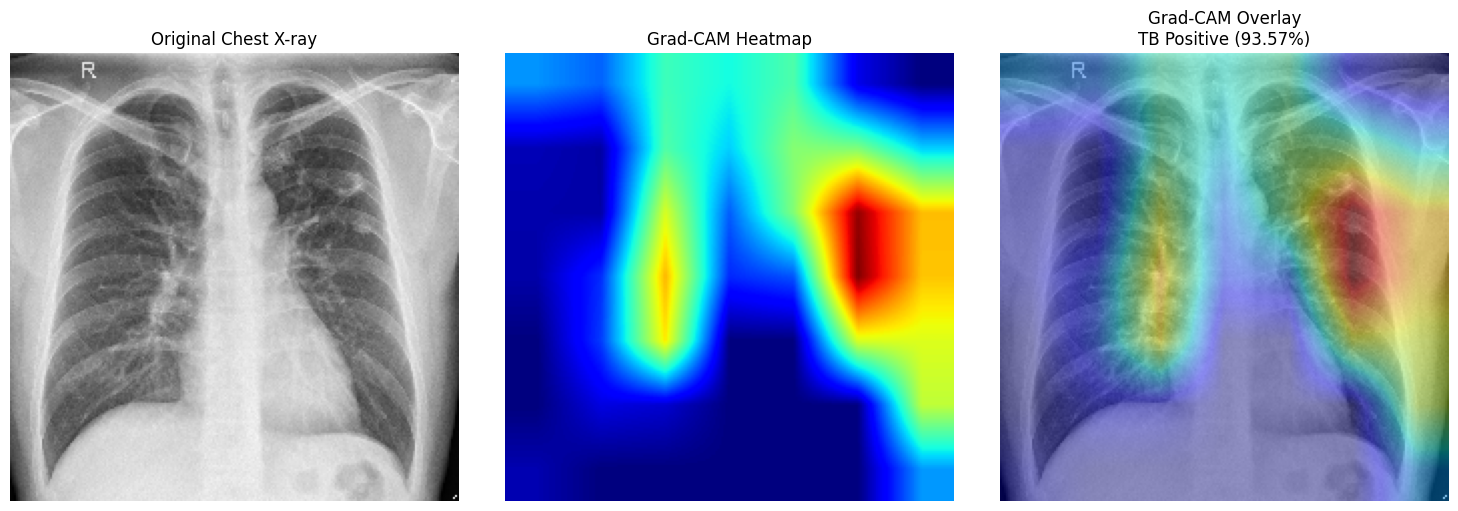

Grad-CAM visualisation saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/Model_Integration/verified_gradcam_overlay.png


In [ ]:
import matplotlib.pyplot as plt

# Using the verified image and heatmap
image = fresh_result["image_batch"][0].numpy() / 255.0

# Resizing the heatmap to match the chest X-ray
heatmap_resized = tf.image.resize(
    verified_heatmap[0, :, :, None],
    (224, 224),
    method="bilinear"
).numpy()[:, :, 0]

# Creating a coloured heatmap
coloured_heatmap = plt.get_cmap("jet")(heatmap_resized)[..., :3]

# Blending the heatmap with the original image
overlay = 0.6 * image + 0.4 * coloured_heatmap
overlay = np.clip(overlay, 0, 1)

# Displaying the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f'Grad-CAM Overlay\n'
    f'{fresh_result["predicted_class"]} '
    f'({fresh_result["tb_probability"]:.2%})'
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

output_path = INTEGRATION_DIR / "verified_gradcam_overlay.png"

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Grad-CAM visualisation saved to:", output_path)

In [ ]:
# Creating a dedicated directory for application integration files

APP_DIR = PROJECT_ROOT / "07_App_Integration"

APP_DIR.mkdir(parents=True, exist_ok=True)

print("Application integration directory:", APP_DIR)
print("Directory exists:", APP_DIR.exists())

Application integration directory: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration
Directory exists: True


In [ ]:
module_code = '''
import io
from pathlib import Path

import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt


@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.reverse(inputs, axis=[-1]) - tf.constant(
            [103.939, 116.779, 123.68],
            dtype=tf.float32
        )

    def get_config(self):
        return super().get_config()


def load_tb_model(model_path):
    return tf.keras.models.load_model(
        str(model_path),
        custom_objects={
            "ResNet50Preprocessing": ResNet50Preprocessing
        },
        compile=False
    )


def preprocess_image(image_input):

    if isinstance(image_input, (str, Path)):
        image_bytes = tf.io.read_file(str(image_input))

    elif isinstance(image_input, bytes):
        image_bytes = image_input

    elif hasattr(image_input, "getvalue"):
        image_bytes = image_input.getvalue()

    else:
        raise TypeError("Unsupported image input type.")

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    return tf.expand_dims(image, axis=0)


def predict_tb(model, image_input):

    image_batch = preprocess_image(image_input)

    probability = float(
        model(image_batch, training=False).numpy()[0][0]
    )

    predicted_class = (
        "TB Positive" if probability >= 0.5 else "TB Negative"
    )

    return {
        "predicted_class": predicted_class,
        "tb_probability": probability,
        "image_batch": image_batch
    }


def generate_gradcam(model, image_batch, positive_class=True):

    backbone = model.get_layer("resnet50")
    target_layer = backbone.get_layer("conv5_block3_out")

    feature_extractor = tf.keras.Model(
        backbone.input,
        [target_layer.output, backbone.output]
    )

    backbone_index = model.layers.index(backbone)
    classification_layers = model.layers[backbone_index + 1:]

    with tf.GradientTape() as tape:

        x = tf.convert_to_tensor(image_batch, dtype=tf.float32)

        for layer in model.layers[:backbone_index]:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue
            x = layer(x, training=False)

        conv_outputs, x = feature_extractor(x, training=False)
        tape.watch(conv_outputs)

        for layer in classification_layers:
            x = layer(x, training=False)

        class_score = x[:, 0] if positive_class else 1.0 - x[:, 0]

    gradients = tape.gradient(class_score, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients[:, None, None, :],
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    heatmap = heatmap / (
        tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8
    )

    return heatmap.numpy()


def create_gradcam_overlay(image_batch, heatmap, alpha=0.4):

    image = image_batch[0].numpy() / 255.0

    resized_heatmap = tf.image.resize(
        heatmap[0, :, :, None],
        (224, 224),
        method="bilinear"
    ).numpy()[:, :, 0]

    coloured_heatmap = plt.get_cmap("jet")(resized_heatmap)[..., :3]

    overlay = (1 - alpha) * image + alpha * coloured_heatmap

    overlay = np.clip(overlay, 0, 1)

    return overlay
'''

module_path = APP_DIR / "tb_model_inference.py"

module_path.write_text(module_code, encoding="utf-8")

print("Python module created successfully!")
print("Module location:", module_path)
print("File size:", module_path.stat().st_size, "bytes")

Python module created successfully!
Module location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference.py
File size: 3518 bytes


In [ ]:
import sys
import importlib

# Making the integration folder accessible to Python
sys.path.insert(0, str(APP_DIR))

# Importing our reusable module
import tb_model_inference

importlib.reload(tb_model_inference)

# Loading the model through the module
app_model = tb_model_inference.load_tb_model(MODEL_PATH)

# Generating a prediction through the module
app_result = tb_model_inference.predict_tb(
    app_model,
    test_image_path
)

print("MODULE INTEGRATION TEST")
print("-----------------------")

print("Model:", app_model.name)
print("Image:", test_image_path.name)
print("Predicted class:", app_result["predicted_class"])
print("TB probability:", f'{app_result["tb_probability"]:.2%}')
print("Input shape:", app_result["image_batch"].shape)

# Comparing with our verified notebook prediction
probability_difference = abs(
    app_result["tb_probability"]
    - fresh_result["tb_probability"]
)

print("\nProbability difference:", f"{probability_difference:.6f}")

assert app_result["predicted_class"] == fresh_result["predicted_class"]
assert probability_difference < 0.01

print("\nModule prediction verification PASSED!")

MODULE INTEGRATION TEST
-----------------------
Model: NIH_Pretrained_ResNet50_TB
Image: CHNCXR_0333_1.png
Predicted class: TB Positive
TB probability: 93.57%
Input shape: (1, 224, 224, 3)

Probability difference: 0.000000

Module prediction verification PASSED!


In [ ]:
# Generating Grad-CAM using the standalone module
app_heatmap = tb_model_inference.generate_gradcam(
    app_model,
    app_result["image_batch"],
    positive_class=(
        app_result["predicted_class"] == "TB Positive"
    )
)

# Generating the overlay using the standalone module
app_overlay = tb_model_inference.create_gradcam_overlay(
    app_result["image_batch"],
    app_heatmap
)

print("MODULE GRAD-CAM TEST")
print("--------------------")

print("Image:", test_image_path.name)
print("Prediction:", app_result["predicted_class"])
print("TB probability:", f'{app_result["tb_probability"]:.2%}')

print("\nHeatmap shape:", app_heatmap.shape)
print("Heatmap maximum:", app_heatmap.max())
print("Overlay shape:", app_overlay.shape)

# Verifying the outputs
assert app_heatmap.shape == (1, 7, 7)
assert np.isfinite(app_heatmap).all()
assert app_heatmap.max() > 0

assert app_overlay.shape == (224, 224, 3)
assert np.isfinite(app_overlay).all()

# Comparing against our verified notebook heatmap
heatmap_difference = np.max(
    np.abs(app_heatmap - verified_heatmap)
)

print(
    "\nMaximum heatmap difference:",
    f"{heatmap_difference:.6f}"
)

print("\nModule Grad-CAM verification PASSED!")

MODULE GRAD-CAM TEST
--------------------
Image: CHNCXR_0333_1.png
Prediction: TB Positive
TB probability: 93.57%

Heatmap shape: (1, 7, 7)
Heatmap maximum: 0.99999934
Overlay shape: (224, 224, 3)

Maximum heatmap difference: 0.000000

Module Grad-CAM verification PASSED!


In [ ]:
import io

# Simulating an image uploaded through Streamlit
with open(test_image_path, "rb") as file:
    uploaded_bytes = file.read()

uploaded_file = io.BytesIO(uploaded_bytes)

# Generating predictions using both input methods
bytes_result = tb_model_inference.predict_tb(
    app_model,
    uploaded_bytes
)

upload_result = tb_model_inference.predict_tb(
    app_model,
    uploaded_file
)

print("STREAMLIT UPLOAD COMPATIBILITY TEST")
print("-----------------------------------")

print("Image:", test_image_path.name)

print(
    "File path prediction:",
    f'{app_result["tb_probability"]:.2%}'
)

print(
    "Raw bytes prediction:",
    f'{bytes_result["tb_probability"]:.2%}'
)

print(
    "Uploaded file prediction:",
    f'{upload_result["tb_probability"]:.2%}'
)

# Comparing the probabilities
bytes_difference = abs(
    app_result["tb_probability"]
    - bytes_result["tb_probability"]
)

upload_difference = abs(
    app_result["tb_probability"]
    - upload_result["tb_probability"]
)

print("\nRaw bytes difference:", f"{bytes_difference:.6f}")
print("Uploaded file difference:", f"{upload_difference:.6f}")

assert bytes_difference < 1e-5
assert upload_difference < 1e-5

print("\nStreamlit upload compatibility test PASSED!")

STREAMLIT UPLOAD COMPATIBILITY TEST
-----------------------------------
Image: CHNCXR_0333_1.png
File path prediction: 93.57%
Raw bytes prediction: 93.57%
Uploaded file prediction: 93.57%

Raw bytes difference: 0.000000
Uploaded file difference: 0.000000

Streamlit upload compatibility test PASSED!


In [ ]:
def run_complete_inference(image_input):

    prediction = tb_model_inference.predict_tb(
        app_model,
        image_input
    )

    heatmap = tb_model_inference.generate_gradcam(
        app_model,
        prediction["image_batch"],
        positive_class=(
            prediction["predicted_class"] == "TB Positive"
        )
    )

    overlay = tb_model_inference.create_gradcam_overlay(
        prediction["image_batch"],
        heatmap
    )

    return {
        "predicted_class": prediction["predicted_class"],
        "tb_probability": prediction["tb_probability"],
        "heatmap": heatmap,
        "overlay": overlay
    }


# Simulating a complete Streamlit prediction
complete_result = run_complete_inference(uploaded_bytes)

print("COMPLETE INFERENCE WORKFLOW")
print("---------------------------")
print("Image:", test_image_path.name)
print("Prediction:", complete_result["predicted_class"])
print(
    "TB probability:",
    f'{complete_result["tb_probability"]:.2%}'
)
print("Heatmap shape:", complete_result["heatmap"].shape)
print("Overlay shape:", complete_result["overlay"].shape)

assert complete_result["heatmap"].shape == (1, 7, 7)
assert complete_result["overlay"].shape == (224, 224, 3)
assert np.isfinite(complete_result["heatmap"]).all()
assert np.isfinite(complete_result["overlay"]).all()

print("\nComplete inference workflow PASSED!")

COMPLETE INFERENCE WORKFLOW
---------------------------
Image: CHNCXR_0333_1.png
Prediction: TB Positive
TB probability: 93.57%
Heatmap shape: (1, 7, 7)
Overlay shape: (224, 224, 3)

Complete inference workflow PASSED!


In [ ]:
workflow_code = '''

def run_complete_inference(model, image_input):

    prediction = predict_tb(model, image_input)

    heatmap = generate_gradcam(
        model,
        prediction["image_batch"],
        positive_class=(
            prediction["predicted_class"] == "TB Positive"
        )
    )

    overlay = create_gradcam_overlay(
        prediction["image_batch"],
        heatmap
    )

    return {
        "predicted_class": prediction["predicted_class"],
        "tb_probability": prediction["tb_probability"],
        "heatmap": heatmap,
        "overlay": overlay
    }
'''

# Avoiding the addition of the function more than once
existing_code = module_path.read_text(encoding="utf-8")

if "def run_complete_inference(" not in existing_code:
    module_path.write_text(
        existing_code + workflow_code,
        encoding="utf-8"
    )
    print("Complete inference workflow added successfully!")
else:
    print("Complete inference workflow already exists.")

print("Module location:", module_path)
print("Updated file size:", module_path.stat().st_size, "bytes")

Complete inference workflow added successfully!
Module location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference.py
Updated file size: 4085 bytes


In [ ]:
# Reloading the updated Python module
importlib.invalidate_caches()
importlib.reload(tb_model_inference)

# Running the complete workflow using the module
final_result = tb_model_inference.run_complete_inference(
    app_model,
    uploaded_bytes
)

print("FINAL MODULE VERIFICATION")
print("-------------------------")

print("Image:", test_image_path.name)
print("Prediction:", final_result["predicted_class"])
print(
    "TB probability:",
    f'{final_result["tb_probability"]:.2%}'
)

print("Heatmap shape:", final_result["heatmap"].shape)
print("Overlay shape:", final_result["overlay"].shape)

# Comparing with our previously verified results
probability_difference = abs(
    final_result["tb_probability"]
    - fresh_result["tb_probability"]
)

print(
    "\nProbability difference:",
    f"{probability_difference:.6f}"
)

assert final_result["predicted_class"] == fresh_result["predicted_class"]
assert probability_difference < 0.01

assert final_result["heatmap"].shape == (1, 7, 7)
assert final_result["overlay"].shape == (224, 224, 3)

assert np.isfinite(final_result["heatmap"]).all()
assert np.isfinite(final_result["overlay"]).all()

print("\nFINAL MODULE VERIFICATION PASSED!")

FINAL MODULE VERIFICATION
-------------------------
Image: CHNCXR_0333_1.png
Prediction: TB Positive
TB probability: 93.57%
Heatmap shape: (1, 7, 7)
Overlay shape: (224, 224, 3)

Probability difference: 0.000000

FINAL MODULE VERIFICATION PASSED!


In [ ]:
import shutil

HANDOVER_DIR = APP_DIR / "Jaden_Handover"
HANDOVER_DIR.mkdir(parents=True, exist_ok=True)

# Copy the reusable inference module
shutil.copy2(
    module_path,
    HANDOVER_DIR / "tb_model_inference.py"
)

# Copy the final trained ResNet50 checkpoint
shutil.copy2(
    MODEL_PATH,
    HANDOVER_DIR / "nih_tb_final_selected.keras"
)

print("HANDOVER PACKAGE")
print("----------------")

for file in HANDOVER_DIR.iterdir():
    print(
        file.name,
        "-",
        f"{file.stat().st_size / (1024 * 1024):.2f} MB"
    )

print("\nHandover files copied successfully!")

HANDOVER PACKAGE
----------------
tb_model_inference.py - 0.00 MB
nih_tb_final_selected.keras - 207.71 MB

Handover files copied successfully!


In [ ]:
readme_text = """# Insight Hunters — ResNet50 Integration Guide

## 1. Overview

This package contains the final NIH-pretrained ResNet50 model
developed for the Insight Hunters tuberculosis detection project.

The model accepts chest X-ray images and generates:
- A TB-positive or TB-negative classification
- A TB-positive prediction score
- A Grad-CAM heatmap
- A Grad-CAM overlay

The model achieved 87.50% accuracy and 83.05% sensitivity
on the held-out test dataset of 120 chest X-ray images.

These results are experimental and do not establish
clinical reliability.

## 2. Package Contents

Jaden_Handover/
    tb_model_inference.py
    nih_tb_final_selected.keras
    README.md

## 3. Required Python Libraries

Install the following dependencies:

    pip install tensorflow numpy pillow matplotlib streamlit

Use a TensorFlow/Keras environment compatible with the
saved model checkpoint.

## 4. Streamlit Integration Example

Place the model checkpoint and Python module in the same
directory as the Streamlit application, or update the paths.

Example:

    import streamlit as st
    from pathlib import Path
    from PIL import Image

    from tb_model_inference import (
        load_tb_model,
        run_complete_inference
    )

    MODEL_PATH = Path(__file__).resolve().parent / "nih_tb_final_selected.keras"

    @st.cache_resource
    def get_model():
        return load_tb_model(MODEL_PATH)

    model = get_model()

    st.title("Insight Hunters — TB Detection")

    uploaded_file = st.file_uploader(
        "Upload a chest X-ray",
        type=["png", "jpg", "jpeg"]
    )

    if uploaded_file is not None:

        result = run_complete_inference(
            model,
            uploaded_file
        )

        st.write("Prediction:", result["predicted_class"])

        st.write(
            "TB-positive model score:",
            f'{result["tb_probability"]:.2%}'
        )

        st.image(
            Image.fromarray(
                (result["overlay"] * 255).astype("uint8")
            ),
            caption="Grad-CAM Visualisation"
        )

        st.warning(
            "Research prototype only. Not intended for "
            "medical diagnosis or clinical decision-making."
        )

## 5. Important Implementation Notes

- Images are resized to 224 x 224 using TensorFlow.
- Images are converted to RGB.
- The model includes its own ResNet50 preprocessing layer.
- Do not apply ResNet50 preprocessing a second time.
- A threshold of 0.5 determines the predicted class.
- Grad-CAM uses the conv5_block3_out feature layer.
- Heatmaps highlight regions influencing model predictions.
- Heatmaps do not identify confirmed tuberculosis lesions.
- The model score is not a clinically calibrated disease probability.
- Standard PNG and JPEG images are supported.
- DICOM images are not currently supported.
- The model is intended for research and demonstration purposes only.

## 6. Verification

The inference pipeline reproduced all 120 classifications
from the original held-out test evaluation.

The complete workflow was also tested using image paths,
raw image bytes and uploaded file objects.

Final verification image:
CHNCXR_0333_1.png

Expected classification:
TB Positive

Expected TB-positive model score:
Approximately 93.57%

## 7. Deployment Considerations

The model checkpoint is approximately 208 MB.

Ensure that the deployment environment has sufficient
memory and supports the required TensorFlow dependencies.

Before the final demonstration, test the application
in its actual deployment environment.

Do not upload identifiable patient images to a public
demonstration application without appropriate authorisation.
"""

readme_path = HANDOVER_DIR / "README.md"

readme_path.write_text(
    readme_text,
    encoding="utf-8"
)

print("Integration guide created successfully!")
print("Location:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")

Integration guide created successfully!
Location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/Jaden_Handover/README.md
File size: 3670 bytes


In [ ]:
required_files = [
    "tb_model_inference.py",
    "nih_tb_final_selected.keras",
    "README.md"
]

print("FINAL HANDOVER PACKAGE VERIFICATION")
print("-----------------------------------")

all_files_valid = True

for filename in required_files:
    file_path = HANDOVER_DIR / filename

    exists = file_path.is_file()
    has_content = exists and file_path.stat().st_size > 0

    status = "PASS" if has_content else "FAIL"

    print(f"{filename}: {status}")

    if not has_content:
        all_files_valid = False

assert all_files_valid, "Handover package is incomplete."

print("\nAll required handover files verified!")

FINAL HANDOVER PACKAGE VERIFICATION
-----------------------------------
tb_model_inference.py: PASS
nih_tb_final_selected.keras: PASS
README.md: PASS

All required handover files verified!


In [ ]:
VALIDATION_ROOT = PROJECT_ROOT / "08_Image_Validation"

VALIDATION_DATA_DIR = VALIDATION_ROOT / "Dataset"
VALIDATION_RESULTS_DIR = VALIDATION_ROOT / "Results"
VALIDATION_MODELS_DIR = VALIDATION_ROOT / "Models"

for directory in [
    VALIDATION_DATA_DIR,
    VALIDATION_RESULTS_DIR,
    VALIDATION_MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("IMAGE VALIDATION WORKSPACE")
print("--------------------------")

print("Dataset directory:", VALIDATION_DATA_DIR)
print("Results directory:", VALIDATION_RESULTS_DIR)
print("Models directory:", VALIDATION_MODELS_DIR)

print("\nValidation workspace created successfully!")

IMAGE VALIDATION WORKSPACE
--------------------------
Dataset directory: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Dataset
Results directory: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Results
Models directory: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Models

Validation workspace created successfully!


In [ ]:
from pathlib import Path

# Locating our existing chest X-ray dataset
XRAY_ROOT = PROJECT_ROOT / "02_Data_Splits"

print("AVAILABLE CHEST X-RAY IMAGES")
print("----------------------------")

for split in ["train", "val", "test"]:
    split_dir = XRAY_ROOT / split

    total = 0

    for category in ["tb_negative", "tb_positive"]:
        category_dir = split_dir / category

        images = [
            file for file in category_dir.iterdir()
            if file.suffix.lower() in [".png", ".jpg", ".jpeg"]
        ] if category_dir.exists() else []

        print(f"{split}/{category}: {len(images)} images")
        total += len(images)

    print(f"Total {split}: {total}\n")

AVAILABLE CHEST X-RAY IMAGES
----------------------------
train/tb_negative: 284 images
train/tb_positive: 276 images
Total train: 560

val/tb_negative: 61 images
val/tb_positive: 59 images
Total val: 120

test/tb_negative: 61 images
test/tb_positive: 59 images
Total test: 120



In [ ]:
import tensorflow as tf
import numpy as np

# Loading CIFAR-10
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("CIFAR-10 DATASET")
print("----------------")

print("Training images:", len(x_train))
print("Testing images:", len(x_test))
print("Image dimensions:", x_train.shape[1:])
print("Number of classes:", len(class_names))

print("\nDataset loaded successfully!")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3627s 21us/step
CIFAR-10 DATASET
----------------
Training images: 50000
Testing images: 10000
Image dimensions: (32, 32, 3)
Number of classes: 10

Dataset loaded successfully!


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# Selecting 680 images from the CIFAR-10 training data
train_val_indices, _ = train_test_split(
    np.arange(len(x_train)),
    train_size=680,
    stratify=y_train.flatten(),
    random_state=SEED
)

# Splitting into 560 training and 120 validation images
train_indices, val_indices = train_test_split(
    train_val_indices,
    train_size=560,
    stratify=y_train[train_val_indices].flatten(),
    random_state=SEED
)

# Selecting 120 images from the CIFAR-10 test data
test_indices, _ = train_test_split(
    np.arange(len(x_test)),
    train_size=120,
    stratify=y_test.flatten(),
    random_state=SEED
)

non_xray_train = x_train[train_indices]
non_xray_val = x_train[val_indices]
non_xray_test = x_test[test_indices]

print("NON-X-RAY DATASET SELECTION")
print("---------------------------")
print("Training images:", len(non_xray_train))
print("Validation images:", len(non_xray_val))
print("Testing images:", len(non_xray_test))

print("\nSelection completed successfully!")

NON-X-RAY DATASET SELECTION
---------------------------
Training images: 560
Validation images: 120
Testing images: 120

Selection completed successfully!


In [ ]:
import shutil
from PIL import Image

# Creating the dataset folders
for split in ["train", "val", "test"]:
    for category in ["non_xray", "chest_xray"]:
        (VALIDATION_DATA_DIR / split / category).mkdir(
            parents=True,
            exist_ok=True
        )

# Copying the existing chest X-rays
for split in ["train", "val", "test"]:
    for tb_class in ["tb_negative", "tb_positive"]:

        source_dir = XRAY_ROOT / split / tb_class
        destination_dir = VALIDATION_DATA_DIR / split / "chest_xray"

        for image_path in source_dir.iterdir():
            if image_path.suffix.lower() in [".png", ".jpg", ".jpeg"]:

                destination = destination_dir / image_path.name

                if not destination.exists():
                    shutil.copy2(image_path, destination)

# Saving the selected CIFAR-10 images
non_xray_splits = {
    "train": non_xray_train,
    "val": non_xray_val,
    "test": non_xray_test
}

for split, images in non_xray_splits.items():

    destination_dir = VALIDATION_DATA_DIR / split / "non_xray"

    for index, image_array in enumerate(images):

        image_path = destination_dir / f"cifar_{index:04d}.png"

        if not image_path.exists():
            Image.fromarray(image_array).save(image_path)

# Verifying the dataset counts
print("IMAGE VALIDATION DATASET")
print("------------------------")

for split in ["train", "val", "test"]:

    xray_count = len(
        list((VALIDATION_DATA_DIR / split / "chest_xray").glob("*"))
    )

    non_xray_count = len(
        list((VALIDATION_DATA_DIR / split / "non_xray").glob("*"))
    )

    print(
        f"{split}: {xray_count} chest X-rays, "
        f"{non_xray_count} non-X-rays"
    )

print("\nDataset organisation completed!")

IMAGE VALIDATION DATASET
------------------------
train: 560 chest X-rays, 560 non-X-rays
val: 120 chest X-rays, 120 non-X-rays
test: 120 chest X-rays, 120 non-X-rays

Dataset organisation completed!


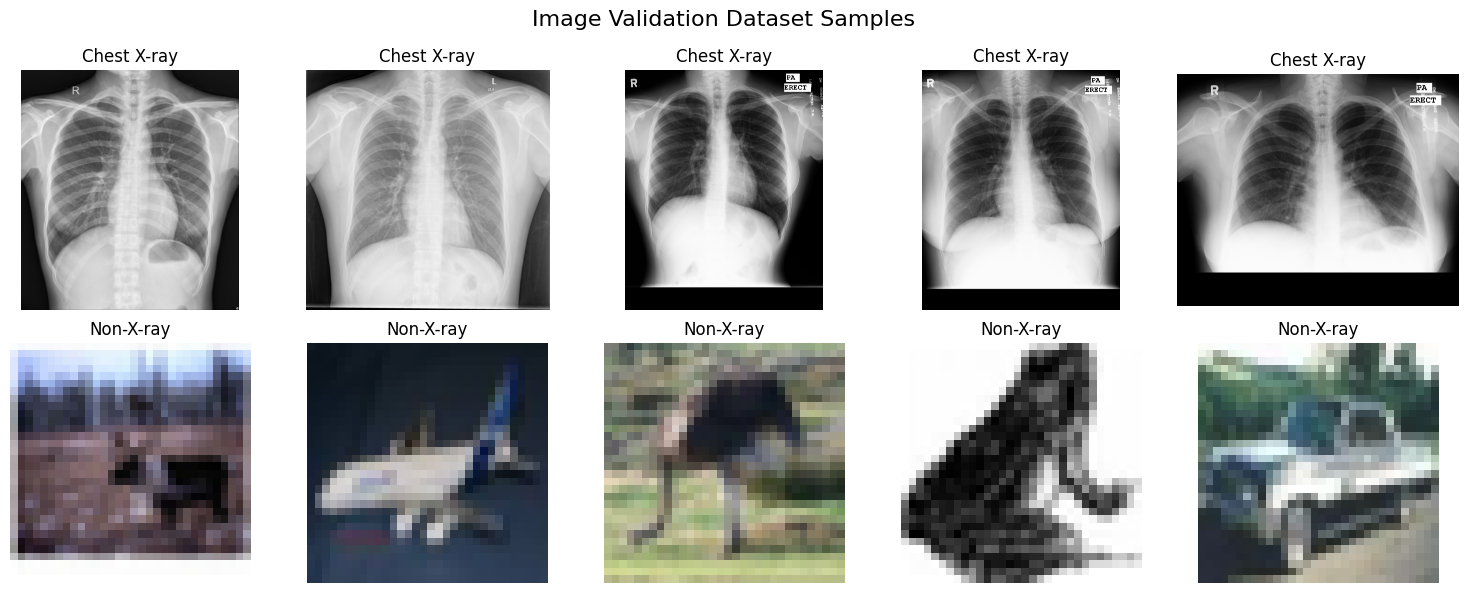

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

categories = ["chest_xray", "non_xray"]

for row, category in enumerate(categories):

    image_dir = VALIDATION_DATA_DIR / "train" / category

    image_paths = list(image_dir.glob("*.png"))
    selected_images = random.sample(image_paths, 5)

    for col, image_path in enumerate(selected_images):

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            "Chest X-ray" if category == "chest_xray"
            else "Non-X-ray"
        )
        axes[row, col].axis("off")

plt.suptitle("Image Validation Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()

Following the visualisation of our initial dataset, noticeable differences were identified between the chest X-rays and non-X-ray images, particularly regarding image resolution and quality. These differences raised concerns that the validator could potentially rely on superficial image characteristics rather than learning to recognise chest X-rays. To address this, we decided to explore higher-resolution and more diverse non-X-ray datasets, allowing us to develop a more reliable validation model whilst reducing the risk of misleading classification results.

In [ ]:
import importlib.util

libraries = [
    "tensorflow",
    "datasets",
    "huggingface_hub",
    "PIL",
    "requests"
]

print("DATASET DOWNLOAD ENVIRONMENT")
print("----------------------------")

for library in libraries:
    installed = importlib.util.find_spec(library) is not None

    print(
        f"{library}:",
        "Available" if installed else "Not installed"
    )

DATASET DOWNLOAD ENVIRONMENT
----------------------------
tensorflow: Available
datasets: Available
huggingface_hub: Available
PIL: Available
requests: Available


In [ ]:
%pip install -q importlib_resources

In [ ]:
import tensorflow_datasets as tfds

print("DOWNLOADING HIGHER-QUALITY PHOTOGRAPHS")
print("--------------------------------------")

pet_dataset, pet_info = tfds.load(
    "oxford_iiit_pet",
    split="train",
    with_info=True,
    shuffle_files=False,
    data_dir="/content/tensorflow_datasets"
)

print("Dataset downloaded successfully!")
print("Number of images:", pet_info.splits["train"].num_examples)

DOWNLOADING HIGHER-QUALITY PHOTOGRAPHS
--------------------------------------


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tensorflow_datasets/oxford_iiit_pet/incomplete.CBFNO6_4.0.0/oxford_iiit_pet-train.tfrecord-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tensorflow_datasets/oxford_iiit_pet/incomplete.CBFNO6_4.0.0/oxford_iiit_pet-test.tfrecord-[…

Dataset oxford_iiit_pet downloaded and prepared to /content/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Dataset downloaded successfully!
Number of images: 3680


In [ ]:
import numpy as np

image_dimensions = []

for sample in pet_dataset.take(100):
    image = sample["image"].numpy()
    image_dimensions.append(image.shape)

heights = [shape[0] for shape in image_dimensions]
widths = [shape[1] for shape in image_dimensions]

print("OXFORD-IIIT PET IMAGE INSPECTION")
print("--------------------------------")

print("Images inspected:", len(image_dimensions))
print("Minimum dimensions:", min(heights), "x", min(widths))
print("Maximum dimensions:", max(heights), "x", max(widths))
print("Average height:", round(np.mean(heights)))
print("Average width:", round(np.mean(widths)))

print("\nSample image dimensions:")
for shape in image_dimensions[:5]:
    print(shape)

OXFORD-IIIT PET IMAGE INSPECTION
--------------------------------
Images inspected: 100
Minimum dimensions: 163 x 200
Maximum dimensions: 900 x 720
Average height: 394
Average width: 426

Sample image dimensions:
(500, 500, 3)
(313, 500, 3)
(500, 333, 3)
(375, 500, 3)
(500, 333, 3)


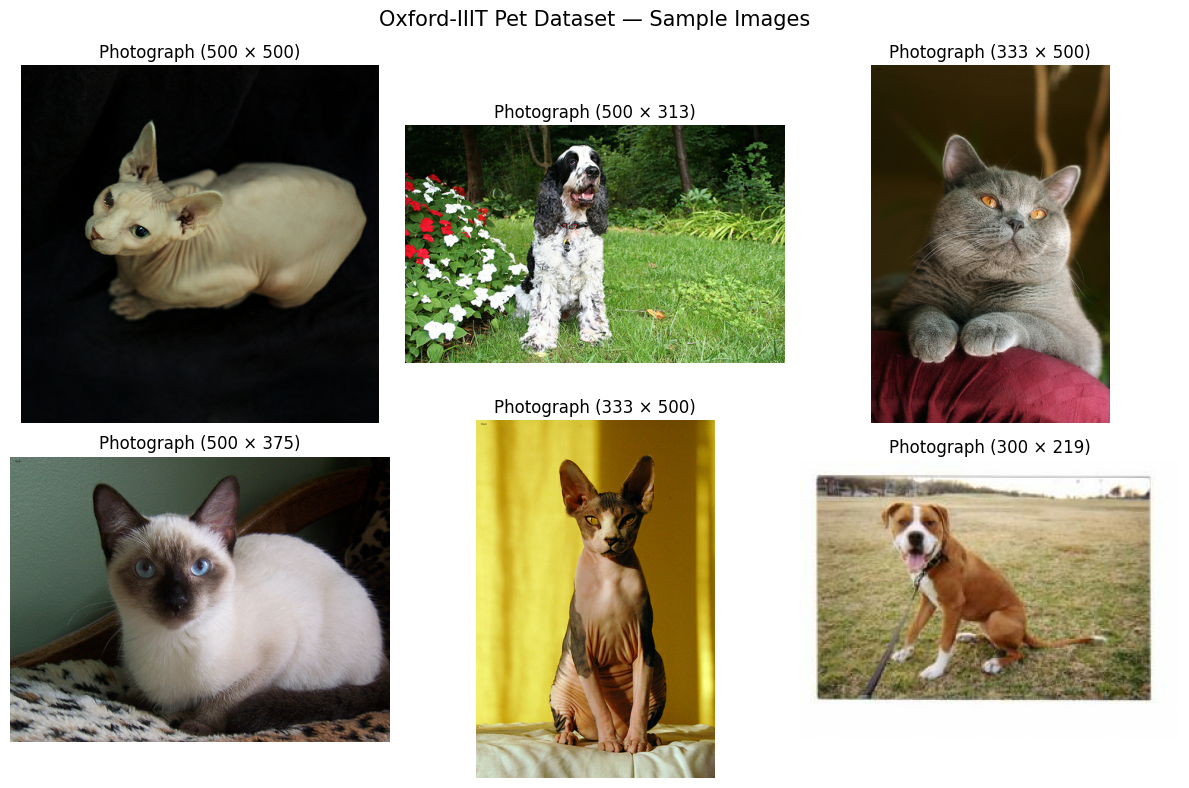

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, sample in zip(axes.flat, pet_dataset.take(6)):

    image = sample["image"].numpy()

    ax.imshow(image)
    ax.set_title(
        f"Photograph ({image.shape[1]} × {image.shape[0]})"
    )
    ax.axis("off")

plt.suptitle(
    "Oxford-IIIT Pet Dataset — Sample Images",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import numpy as np

COLLECTION_DIR = VALIDATION_ROOT / "Photo_Collection"
PET_DIR = COLLECTION_DIR / "pets"

PET_DIR.mkdir(parents=True, exist_ok=True)

saved_count = 0

for sample in pet_dataset.take(300):

    image_array = sample["image"].numpy()

    image = Image.fromarray(image_array).convert("RGB")

    image_path = PET_DIR / f"pet_{saved_count:04d}.jpg"

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    saved_count += 1

print("PET PHOTOGRAPH COLLECTION")
print("-------------------------")
print("Photographs saved:", saved_count)
print("Destination:", PET_DIR)

PET PHOTOGRAPH COLLECTION
-------------------------
Photographs saved: 300
Destination: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/pets


In [ ]:
import tensorflow_datasets as tfds

print("DOWNLOADING CALTECH-101 DATASET")
print("------------------------------")

caltech_dataset, caltech_info = tfds.load(
    "caltech101",
    split="train",
    with_info=True,
    shuffle_files=False,
    data_dir="/content/tensorflow_datasets"
)

print("\nDataset downloaded successfully!")
print("Number of images:", caltech_info.splits["train"].num_examples)
print("Number of categories:", caltech_info.features["label"].num_classes)

DOWNLOADING CALTECH-101 DATASET
------------------------------


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

...

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tensorflow_datasets/caltech101/incomplete.B9M80O_3.0.2/caltech101-train.tfrecord-[0-9][0-9]…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tensorflow_datasets/caltech101/incomplete.B9M80O_3.0.2/caltech101-test.tfrecord-[0-9][0-9][…

Dataset caltech101 downloaded and prepared to /content/tensorflow_datasets/caltech101/3.0.2. Subsequent calls will reuse this data.

Dataset downloaded successfully!
Number of images: 3060
Number of categories: 102


In [ ]:
# Retrieving the Caltech-101 category names
caltech_class_names = (
    caltech_info.features["label"].names
)

print("CALTECH-101 AVAILABLE CATEGORIES")
print("--------------------------------")

for index, category in enumerate(caltech_class_names):
    print(f"{index:3d}: {category}")

print("\nTotal categories:", len(caltech_class_names))

CALTECH-101 AVAILABLE CATEGORIES
--------------------------------
  0: accordion
  1: airplanes
  2: anchor
  3: ant
  4: background_google
  5: barrel
  6: bass
  7: beaver
  8: binocular
  9: bonsai
 10: brain
 11: brontosaurus
 12: buddha
 13: butterfly
 14: camera
 15: cannon
 16: car_side
 17: ceiling_fan
 18: cellphone
 19: chair
 20: chandelier
 21: cougar_body
 22: cougar_face
 23: crab
 24: crayfish
 25: crocodile
 26: crocodile_head
 27: cup
 28: dalmatian
 29: dollar_bill
 30: dolphin
 31: dragonfly
 32: electric_guitar
 33: elephant
 34: emu
 35: euphonium
 36: ewer
 37: faces
 38: faces_easy
 39: ferry
 40: flamingo
 41: flamingo_head
 42: garfield
 43: gerenuk
 44: gramophone
 45: grand_piano
 46: hawksbill
 47: headphone
 48: hedgehog
 49: helicopter
 50: ibis
 51: inline_skate
 52: joshua_tree
 53: kangaroo
 54: ketch
 55: lamp
 56: laptop
 57: leopards
 58: llama
 59: lobster
 60: lotus
 61: mandolin
 62: mayfly
 63: menorah
 64: metronome
 65: minaret
 66: motorbikes


In [ ]:
from collections import Counter

# Counting the images in each Caltech-101 category
category_counts = Counter()

for sample in caltech_dataset:
    label = int(sample["label"].numpy())
    category_counts[label] += 1

# The categories we are interested in
selected_categories = [
    "airplanes", "car_side", "motorbikes", "helicopter",
    "faces", "faces_easy",
    "chair", "cellphone", "laptop", "camera", "cup",
    "pagoda", "minaret", "pyramid", "joshua_tree",
    "pizza", "strawberry", "sunflower", "lotus",
    "brain"
]

print("CALTECH-101 CATEGORY AVAILABILITY")
print("---------------------------------")

total_available = 0

for category in selected_categories:

    category_index = caltech_class_names.index(category)
    count = category_counts[category_index]

    print(f"{category:20s}: {count} images")

    total_available += count

print("---------------------------------")
print("Total available:", total_available)

CALTECH-101 CATEGORY AVAILABILITY
---------------------------------
airplanes           : 30 images
car_side            : 30 images
motorbikes          : 30 images
helicopter          : 30 images
faces               : 30 images
faces_easy          : 30 images
chair               : 30 images
cellphone           : 30 images
laptop              : 30 images
camera              : 30 images
cup                 : 30 images
pagoda              : 30 images
minaret             : 30 images
pyramid             : 30 images
joshua_tree         : 30 images
pizza               : 30 images
strawberry          : 30 images
sunflower           : 30 images
lotus               : 30 images
brain               : 30 images
---------------------------------
Total available: 600


In [ ]:
CALTECH_DIR = COLLECTION_DIR / "caltech101"
CALTECH_DIR.mkdir(parents=True, exist_ok=True)

selected_category_indices = {
    caltech_class_names.index(category): category
    for category in selected_categories
}

category_saved_counts = {
    category: 0
    for category in selected_categories
}

for sample in caltech_dataset:

    label = int(sample["label"].numpy())

    if label not in selected_category_indices:
        continue

    category = selected_category_indices[label]

    image_array = sample["image"].numpy()
    image = Image.fromarray(image_array).convert("RGB")

    image_number = category_saved_counts[category]

    image_path = (
        CALTECH_DIR
        / f"{category}_{image_number:03d}.jpg"
    )

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    category_saved_counts[category] += 1

print("CALTECH-101 PHOTOGRAPH COLLECTION")
print("---------------------------------")

for category, count in category_saved_counts.items():
    print(f"{category:20s}: {count}")

print("---------------------------------")
print("Total saved:", sum(category_saved_counts.values()))
print("Destination:", CALTECH_DIR)

CALTECH-101 PHOTOGRAPH COLLECTION
---------------------------------
airplanes           : 30
car_side            : 30
motorbikes          : 30
helicopter          : 30
faces               : 30
faces_easy          : 30
chair               : 30
cellphone           : 30
laptop              : 30
camera              : 30
cup                 : 30
pagoda              : 30
minaret             : 30
pyramid             : 30
joshua_tree         : 30
pizza               : 30
strawberry          : 30
sunflower           : 30
lotus               : 30
brain               : 30
---------------------------------
Total saved: 600
Destination: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/caltech101


In [ ]:
from PIL import Image
import numpy as np

photo_directories = {
    "Oxford-IIIT Pet": PET_DIR,
    "Caltech-101": CALTECH_DIR
}

verification_records = []

for source, directory in photo_directories.items():

    image_paths = sorted(directory.glob("*.jpg"))

    valid_count = 0
    invalid_count = 0

    for image_path in image_paths:

        try:
            with Image.open(image_path) as img:
                img.verify()

            valid_count += 1

        except Exception:
            invalid_count += 1

    verification_records.append({
        "Source": source,
        "Total": len(image_paths),
        "Valid": valid_count,
        "Invalid": invalid_count
    })

print("PHOTOGRAPH COLLECTION VERIFICATION")
print("----------------------------------")

for record in verification_records:
    print(
        f'{record["Source"]}: '
        f'{record["Valid"]} valid, '
        f'{record["Invalid"]} invalid'
    )

total_valid = sum(record["Valid"] for record in verification_records)
total_invalid = sum(record["Invalid"] for record in verification_records)

print("----------------------------------")
print("Total valid photographs:", total_valid)
print("Total invalid photographs:", total_invalid)

assert total_invalid == 0, "Some photographs could not be verified."

print("\nPhotograph collection verification PASSED!")

PHOTOGRAPH COLLECTION VERIFICATION
----------------------------------
Oxford-IIIT Pet: 300 valid, 0 invalid
Caltech-101: 600 valid, 0 invalid
----------------------------------
Total valid photographs: 900
Total invalid photographs: 0

Photograph collection verification PASSED!


In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Collecting the photograph paths and source information
photo_records = []

for source, directory in photo_directories.items():

    for image_path in sorted(directory.glob("*.jpg")):

        photo_records.append({
            "path": str(image_path),
            "source": source
        })

photos_df = pd.DataFrame(photo_records)

# First split: 70% training, 30% remaining
train_df, remaining_df = train_test_split(
    photos_df,
    test_size=0.30,
    stratify=photos_df["source"],
    random_state=42
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["source"],
    random_state=42
)

print("PHOTOGRAPH DATASET SPLITS")
print("-------------------------")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nSource distribution:")
print(
    pd.crosstab(
        pd.concat([
            train_df.assign(split="train"),
            val_df.assign(split="val"),
            test_df.assign(split="test")
        ])["split"],
        pd.concat([
            train_df,
            val_df,
            test_df
        ])["source"]
    )
)

# Ensuring that no images appears in multiple splits
assert set(train_df["path"]).isdisjoint(val_df["path"])
assert set(train_df["path"]).isdisjoint(test_df["path"])
assert set(val_df["path"]).isdisjoint(test_df["path"])

print("\nDataset splitting completed successfully!")

PHOTOGRAPH DATASET SPLITS
-------------------------
Training: 630
Validation: 135
Testing: 135

Source distribution:
source  Caltech-101  Oxford-IIIT Pet
split                               
test             90               45
train           420              210
val              90               45

Dataset splitting completed successfully!


In [ ]:
import hashlib
from collections import defaultdict

# Combining all the photograph splits
all_photos_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test")
], ignore_index=True)

def calculate_file_hash(file_path):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

# Calculating the hashes
all_photos_df["sha256"] = all_photos_df["path"].apply(
    calculate_file_hash
)

# Identifying the duplicate files
duplicate_groups = all_photos_df[
    all_photos_df.duplicated("sha256", keep=False)
]

print("PHOTOGRAPH DUPLICATE VERIFICATION")
print("--------------------------------")

print("Total photographs:", len(all_photos_df))
print("Unique file hashes:", all_photos_df["sha256"].nunique())
print("Duplicate file records:", len(duplicate_groups))

if duplicate_groups.empty:
    print("\nNo exact file duplicates detected!")
else:
    print("\nDuplicate files detected:")
    print(
        duplicate_groups[
            ["path", "source", "split", "sha256"]
        ].sort_values("sha256").to_string(index=False)
    )

PHOTOGRAPH DUPLICATE VERIFICATION
--------------------------------
Total photographs: 900
Unique file hashes: 900
Duplicate file records: 0

No exact file duplicates detected!


In [ ]:
%pip install -q ImageHash

import imagehash
from PIL import Image
from itertools import combinations

# Calculating the perceptual hashes
def calculate_phash(image_path):
    with Image.open(image_path) as img:
        return imagehash.phash(img.convert("RGB"))

all_photos_df["phash"] = all_photos_df["path"].apply(
    calculate_phash
)

# Comparing the images across the different splits
split_pairs = [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]

similar_pairs = []

for split_a, split_b in split_pairs:

    images_a = all_photos_df[
        all_photos_df["split"] == split_a
    ]

    images_b = all_photos_df[
        all_photos_df["split"] == split_b
    ]

    for _, image_a in images_a.iterrows():
        for _, image_b in images_b.iterrows():

            distance = image_a["phash"] - image_b["phash"]

            if distance <= 5:
                similar_pairs.append({
                    "split_a": split_a,
                    "image_a": image_a["path"],
                    "split_b": split_b,
                    "image_b": image_b["path"],
                    "distance": distance
                })

print("CROSS-SPLIT PERCEPTUAL DUPLICATE CHECK")
print("--------------------------------------")
print("Potentially similar image pairs:", len(similar_pairs))

if similar_pairs:
    display(
        pd.DataFrame(similar_pairs)
        .sort_values("distance")
        .head(20)
    )
else:
    print("No potentially similar cross-split images detected.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.1 MB/s eta 0:00:00
CROSS-SPLIT PERCEPTUAL DUPLICATE CHECK
--------------------------------------
Potentially similar image pairs: 2


,split_a,image_a,split_b,image_b,distance
0,train,/content/drive/MyDrive/Insight_Hunters_Project...,val,/content/drive/MyDrive/Insight_Hunters_Project...,0
1,train,/content/drive/MyDrive/Insight_Hunters_Project...,test,/content/drive/MyDrive/Insight_Hunters_Project...,0


VISUAL INSPECTION OF POTENTIAL DUPLICATES
-----------------------------------------


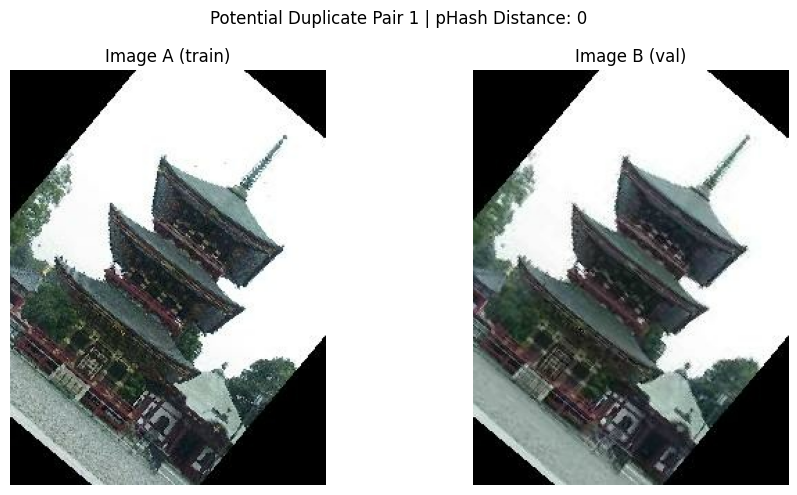


PAIR 1
Image A: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/caltech101/pagoda_003.jpg
Image B: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/caltech101/pagoda_016.jpg
pHash distance: 0
------------------------------------------------------------


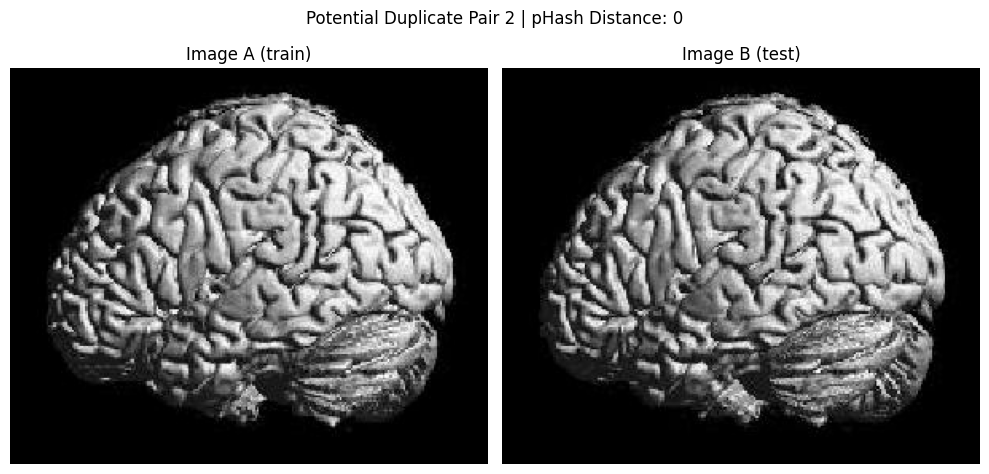


PAIR 2
Image A: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/caltech101/brain_018.jpg
Image B: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Photo_Collection/caltech101/brain_017.jpg
pHash distance: 0
------------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

print("VISUAL INSPECTION OF POTENTIAL DUPLICATES")
print("-----------------------------------------")

for index, pair in enumerate(similar_pairs):

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    image_a = Image.open(pair["image_a"]).convert("RGB")
    image_b = Image.open(pair["image_b"]).convert("RGB")

    axes[0].imshow(image_a)
    axes[0].set_title(f'Image A ({pair["split_a"]})')
    axes[0].axis("off")

    axes[1].imshow(image_b)
    axes[1].set_title(f'Image B ({pair["split_b"]})')
    axes[1].axis("off")

    plt.suptitle(
        f"Potential Duplicate Pair {index + 1} "
        f"| pHash Distance: {pair['distance']}"
    )

    plt.tight_layout()
    plt.show()

    print(f"\nPAIR {index + 1}")
    print("Image A:", pair["image_a"])
    print("Image B:", pair["image_b"])
    print("pHash distance:", pair["distance"])
    print("-" * 60)

In [ ]:
# Identifying the validation/test records involved in confirmed duplicates
paths_to_exclude = set()

for pair in similar_pairs:

    if pair["split_a"] == "train":
        paths_to_exclude.add(pair["image_b"])

    elif pair["split_b"] == "train":
        paths_to_exclude.add(pair["image_a"])

# Removing the duplicate records from both validation and testing
val_df = val_df[
    ~val_df["path"].isin(paths_to_exclude)
].copy()

test_df = test_df[
    ~test_df["path"].isin(paths_to_exclude)
].copy()

# Verifying the updated splits
print("UPDATED PHOTOGRAPH DATASET SPLITS")
print("---------------------------------")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nExcluded duplicate records:", len(paths_to_exclude))

# Confirming that there are no excluded photographs remaining in the evaluation splits
assert not set(val_df["path"]) & paths_to_exclude
assert not set(test_df["path"]) & paths_to_exclude

print("\nConfirmed duplicate records successfully excluded!")

UPDATED PHOTOGRAPH DATASET SPLITS
---------------------------------
Training: 630
Validation: 134
Testing: 134

Excluded duplicate records: 2

Confirmed duplicate records successfully excluded!


In [ ]:
import shutil
from pathlib import Path

# Backup location for original CIFAR-10 negatives
BACKUP_DIR = VALIDATION_ROOT / "CIFAR10_Backup"

# Photograph splits
photo_splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

print("REBUILDING NON-X-RAY DATASET")
print("----------------------------")

for split_name, dataframe in photo_splits.items():

    destination = VALIDATION_DATA_DIR / split_name / "non_xray"
    backup_destination = BACKUP_DIR / split_name

    backup_destination.mkdir(parents=True, exist_ok=True)

    # Backing up the existing files before replacing anything
    existing_files = [
        path for path in destination.iterdir()
        if path.is_file()
    ]

    for file_path in existing_files:
        shutil.copy2(
            file_path,
            backup_destination / file_path.name
        )

    # Removing the existing non-X-ray images
    for file_path in existing_files:
        file_path.unlink()

    # Copying improved photographs
    for _, row in dataframe.iterrows():

        source_path = Path(row["path"])

        # Including the dataset source to prevent filename collisions
        source_prefix = (
            "pet" if row["source"] == "Oxford-IIIT Pet"
            else "caltech"
        )

        destination_path = (
            destination / f"{source_prefix}_{source_path.name}"
        )

        shutil.copy2(source_path, destination_path)

    final_count = len(list(destination.glob("*")))

    print(
        f"{split_name}: "
        f"{final_count} photographs copied"
    )

    assert final_count == len(dataframe)

print("----------------------------")
print("Dataset replacement completed successfully!")
print("CIFAR-10 backup:", BACKUP_DIR)

REBUILDING NON-X-RAY DATASET
----------------------------
train: 630 photographs copied
val: 134 photographs copied
test: 134 photographs copied
----------------------------
Dataset replacement completed successfully!
CIFAR-10 backup: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/CIFAR10_Backup


In [ ]:
from pathlib import Path
from PIL import Image
import hashlib

expected_counts = {
    "train": {"chest_xray": 560, "non_xray": 630},
    "val": {"chest_xray": 120, "non_xray": 134},
    "test": {"chest_xray": 120, "non_xray": 134}
}

print("FINAL VALIDATOR DATASET VERIFICATION")
print("------------------------------------")

total_images = 0

for split_name, classes in expected_counts.items():

    for class_name, expected_count in classes.items():

        folder = VALIDATION_DATA_DIR / split_name / class_name

        image_files = sorted([
            path for path in folder.iterdir()
            if path.is_file()
        ])

        valid_count = 0

        for image_path in image_files:

            with Image.open(image_path) as img:
                img.verify()

            valid_count += 1

        assert valid_count == expected_count, (
            f"{split_name}/{class_name}: "
            f"Expected {expected_count}, found {valid_count}"
        )

        total_images += valid_count

        print(
            f"{split_name:5s} | "
            f"{class_name:12s} | "
            f"{valid_count} valid images"
        )

print("------------------------------------")
print("Total verified images:", total_images)

assert total_images == 1698

# Verifying that the copied photographs match their original files
photo_splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

for split_name, dataframe in photo_splits.items():

    for _, row in dataframe.iterrows():

        original_path = Path(row["path"])

        prefix = (
            "pet" if row["source"] == "Oxford-IIIT Pet"
            else "caltech"
        )

        copied_path = (
            VALIDATION_DATA_DIR
            / split_name
            / "non_xray"
            / f"{prefix}_{original_path.name}"
        )

        assert copied_path.exists()

        assert (
            calculate_file_hash(original_path)
            == calculate_file_hash(copied_path)
        )

print("\nAll copied photographs match their originals!")
print("Dataset verification PASSED!")

FINAL VALIDATOR DATASET VERIFICATION
------------------------------------
train | chest_xray   | 560 valid images
train | non_xray     | 630 valid images
val   | chest_xray   | 120 valid images
val   | non_xray     | 134 valid images
test  | chest_xray   | 120 valid images
test  | non_xray     | 134 valid images
------------------------------------
Total verified images: 1698

All copied photographs match their originals!
Dataset verification PASSED!


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

CLASS_NAMES = ["chest_xray", "non_xray"]

def load_validator_dataset(split_name, shuffle=False):

    dataset_path = VALIDATION_DATA_DIR / split_name

    dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_path,
        labels="inferred",
        label_mode="binary",
        class_names=CLASS_NAMES,
        color_mode="grayscale",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

    # MobileNetV2 expects three input channels.
    # Converting the grayscale images to RGB without restoring colour.
    dataset = dataset.map(
        lambda images, labels: (
            tf.image.grayscale_to_rgb(images),
            labels
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


train_validator_ds = load_validator_dataset(
    "train",
    shuffle=True
)

val_validator_ds = load_validator_dataset("val")

test_validator_ds = load_validator_dataset("test")

print("\nVALIDATOR DATASETS LOADED SUCCESSFULLY")

for images, labels in train_validator_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

print("\nClass mapping:")
print("0 = chest_xray")
print("1 = non_xray")

Found 1190 files belonging to 2 classes.
Found 254 files belonging to 2 classes.
Found 254 files belonging to 2 classes.

VALIDATOR DATASETS LOADED SUCCESSFULLY
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 1)
Pixel range: 0.0 to 255.0

Class mapping:
0 = chest_xray
1 = non_xray


In [ ]:
import tensorflow as tf

# Lightweight image augmentation
validator_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.05),
    tf.keras.layers.RandomTranslation(0.03, 0.03)
], name="validator_augmentation")

# Pretrained MobileNetV2 backbone
validator_backbone = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freezing the pretrained backbone for the initial training
validator_backbone.trainable = False

# Constructing a validator
validator_inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="validator_input"
)

x = validator_augmentation(validator_inputs)

# Converting the pixel values from [0, 255] to [-1, 1]
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = validator_backbone(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

validator_outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="non_xray_probability"
)(x)

validator_model = tf.keras.Model(
    inputs=validator_inputs,
    outputs=validator_outputs,
    name="chest_xray_validator"
)

validator_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("CHEST X-RAY VALIDATOR MODEL")
print("---------------------------")

validator_model.summary()

print("\nModel successfully constructed!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
CHEST X-RAY VALIDATOR MODEL
---------------------------


Model: "chest_xray_validator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ validator_input (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ validator_augmentation          │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ non_xray_probability (Dense)    │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Model successfully constructed!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Saving the best model in our validation project folder
VALIDATOR_MODEL_PATH = (
    VALIDATION_MODELS_DIR / "mobilenetv2_validator_best.keras"
)

VALIDATION_MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Training callbacks
validator_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(VALIDATOR_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Training the classification head
validator_history = validator_model.fit(
    train_validator_ds,
    validation_data=val_validator_ds,
    epochs=15,
    callbacks=validator_callbacks
)

print("\nVALIDATOR TRAINING COMPLETED")
print("----------------------------")
print("Best model saved to:")
print(VALIDATOR_MODEL_PATH)

Epoch 1/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.6269 - auc: 0.6971 - loss: 0.6299 - precision: 0.6322 - recall: 0.6359
Epoch 1: val_loss improved from None to 0.33915, saving model to /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Models/mobilenetv2_validator_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Models/mobilenetv2_validator_best.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 22s 162ms/step - accuracy: 0.7218 - auc: 0.8073 - loss: 0.5373 - precision: 0.7538 - recall: 0.7048 - val_accuracy: 0.9055 - val_auc: 0.9922 - val_loss: 0.3391 - val_precision: 1.0000 - val_recall: 0.8209 - learning_rate: 1.0000e-04
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.8785 - auc: 0.9598 - loss: 0.3407 - precision: 0.8734 - recall: 0.8748
Epoch 2: val_loss improved from 0.33915 to 0.19586, saving model to /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Models/mobilenetv

In [ ]:
import tensorflow as tf

# Loading the best saved validator checkpoint
best_validator_model = tf.keras.models.load_model(
    str(VALIDATOR_MODEL_PATH)
)

print("CHEST X-RAY VALIDATOR — TEST EVALUATION")
print("--------------------------------------")

# Evaluating on the held-out test images
test_results = best_validator_model.evaluate(
    test_validator_ds,
    return_dict=True,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("------------------")

for metric, value in test_results.items():
    print(f"{metric:12s}: {value:.4f}")

print("\nClass mapping:")
print("0 = chest_xray")
print("1 = non_xray")

CHEST X-RAY VALIDATOR — TEST EVALUATION
--------------------------------------
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 121ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0199 - precision: 1.0000 - recall: 1.0000

FINAL TEST RESULTS
------------------
accuracy    : 1.0000
auc         : 1.0000
loss        : 0.0199
precision   : 1.0000
recall      : 1.0000

Class mapping:
0 = chest_xray
1 = non_xray


VALIDATOR CONFUSION MATRIX
--------------------------
[[120   0]
 [  0 134]]

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

 Chest X-ray       1.00      1.00      1.00       120
   Non-X-ray       1.00      1.00      1.00       134

    accuracy                           1.00       254
   macro avg       1.00      1.00      1.00       254
weighted avg       1.00      1.00      1.00       254



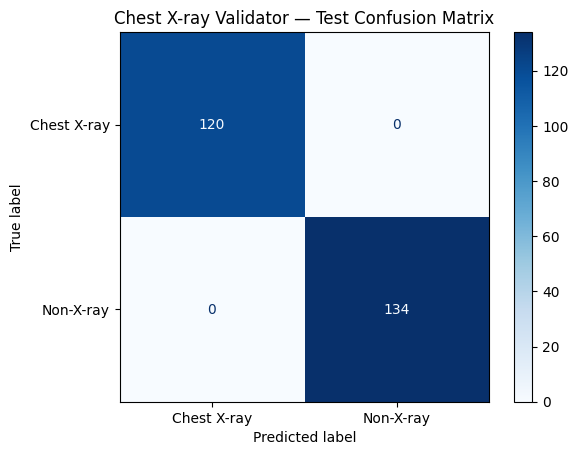


PREDICTION SCORE ANALYSIS
-------------------------

Chest X-ray
Minimum score: 0.000599
Maximum score: 0.257932
Mean score:    0.011604

Non-X-ray
Minimum score: 0.798453
Maximum score: 0.999628
Mean score:    0.974243


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Collecting the true labels and predictions
y_true = []
y_scores = []

for images, labels in test_validator_ds:

    predictions = best_validator_model(
        images,
        training=False
    ).numpy().flatten()

    y_true.extend(labels.numpy().flatten())
    y_scores.extend(predictions)

y_true = np.array(y_true).astype(int)
y_scores = np.array(y_scores)

# Applying default classification thresholds
y_pred = (y_scores >= 0.5).astype(int)

# Generating a confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("VALIDATOR CONFUSION MATRIX")
print("--------------------------")
print(cm)

print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Chest X-ray",
            "Non-X-ray"
        ]
    )
)

# Visualising the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Chest X-ray",
        "Non-X-ray"
    ]
)

display_matrix.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Chest X-ray Validator — Test Confusion Matrix")
plt.show()

# Examining the prediction score ranges
print("\nPREDICTION SCORE ANALYSIS")
print("-------------------------")

for class_label, class_name in [
    (0, "Chest X-ray"),
    (1, "Non-X-ray")
]:

    class_scores = y_scores[y_true == class_label]

    print(f"\n{class_name}")
    print(f"Minimum score: {class_scores.min():.6f}")
    print(f"Maximum score: {class_scores.max():.6f}")
    print(f"Mean score:    {class_scores.mean():.6f}")

In [ ]:
from pathlib import Path
from PIL import Image

ROBUSTNESS_ROOT = VALIDATION_ROOT / "Robustness_Testing"
UNSEEN_PETS_DIR = ROBUSTNESS_ROOT / "Unseen_Pets"

UNSEEN_PETS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Selecting 100 photographs beyond the original 300
unseen_pet_dataset = pet_dataset.skip(300).take(100)

saved_count = 0

for sample in unseen_pet_dataset:

    image_array = sample["image"].numpy()

    image = Image.fromarray(image_array).convert("RGB")

    image_path = (
        UNSEEN_PETS_DIR
        / f"unseen_pet_{saved_count:03d}.jpg"
    )

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    saved_count += 1

print("UNSEEN PET PHOTOGRAPH COLLECTION")
print("--------------------------------")
print("Photographs collected:", saved_count)
print("Destination:", UNSEEN_PETS_DIR)

assert saved_count == 100

print("\nRobustness photograph collection completed!")

UNSEEN PET PHOTOGRAPH COLLECTION
--------------------------------
Photographs collected: 100
Destination: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Unseen_Pets

Robustness photograph collection completed!


In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image

# Collecting the unseen photographs
unseen_image_paths = sorted(
    UNSEEN_PETS_DIR.glob("*.jpg")
)

assert len(unseen_image_paths) == 100

# Preprocessing images exactly as we did during the training
def prepare_validator_image(image_path):

    image = Image.open(image_path).convert("L")
    image = image.resize((224, 224))

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.stack(
        [image_array] * 3,
        axis=-1
    )

    return image_array

# Preparing the batch
unseen_images = np.stack([
    prepare_validator_image(path)
    for path in unseen_image_paths
])

# Generating the predictions
unseen_scores = best_validator_model.predict(
    unseen_images,
    batch_size=16,
    verbose=0
).flatten()

# Classifying using the existing threshold
unseen_predictions = (
    unseen_scores >= 0.5
).astype(int)

correctly_rejected = np.sum(
    unseen_predictions == 1
)

incorrectly_accepted = np.sum(
    unseen_predictions == 0
)

print("UNSEEN PHOTOGRAPH ROBUSTNESS TEST")
print("--------------------------------")

print("Total photographs:", len(unseen_image_paths))
print("Correctly rejected:", correctly_rejected)
print("Incorrectly accepted:", incorrectly_accepted)

print(
    "Rejection accuracy:",
    f"{correctly_rejected / len(unseen_image_paths) * 100:.2f}%"
)

print("\nPREDICTION SCORE ANALYSIS")
print("-------------------------")

print("Minimum score:", round(float(unseen_scores.min()), 6))
print("Maximum score:", round(float(unseen_scores.max()), 6))
print("Mean score:", round(float(unseen_scores.mean()), 6))

print("\nPhotographs incorrectly accepted:")
for path, score in zip(unseen_image_paths, unseen_scores):
    if score < 0.5:
        print(f"{path.name}: {score:.6f}")

UNSEEN PHOTOGRAPH ROBUSTNESS TEST
--------------------------------
Total photographs: 100
Correctly rejected: 100
Incorrectly accepted: 0
Rejection accuracy: 100.00%

PREDICTION SCORE ANALYSIS
-------------------------
Minimum score: 0.79183
Maximum score: 0.999891
Mean score: 0.971836

Photographs incorrectly accepted:


In [ ]:
from pathlib import Path

MEDICAL_TEST_ROOT = (
    VALIDATION_ROOT
    / "Robustness_Testing"
    / "Medical_Images"
)

medical_categories = [
    "hand_xray",
    "dental_xray",
    "skull_xray",
    "ct_scan",
    "brain_mri"
]

for category in medical_categories:

    category_path = MEDICAL_TEST_ROOT / category

    category_path.mkdir(
        parents=True,
        exist_ok=True
    )

print("MEDICAL IMAGE ROBUSTNESS TEST")
print("-----------------------------")

for category in medical_categories:

    category_path = MEDICAL_TEST_ROOT / category

    print(
        f"{category:15s}: "
        f"{category_path}"
    )

print("\nMedical robustness folders created successfully!")

MEDICAL IMAGE ROBUSTNESS TEST
-----------------------------
hand_xray      : /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray
dental_xray    : /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/dental_xray
skull_xray     : /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/skull_xray
ct_scan        : /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/ct_scan
brain_mri      : /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/brain_mri

Medical robustness folders created successfully!


In [ ]:
from medmnist import INFO

print("AVAILABLE MEDICAL IMAGE DATASETS")
print("--------------------------------")

for dataset_name in INFO.keys():
    print(dataset_name)

print("\nRELEVANT DATASET INFORMATION")
print("----------------------------")

candidate_datasets = [
    "headctmnist",
    "organamnist",
    "organcmnist",
    "organsmnist"
]

for dataset_name in candidate_datasets:

    if dataset_name in INFO:

        dataset_info = INFO[dataset_name]

        print(f"\nDataset: {dataset_name}")
        print("Description:", dataset_info.get("description", "N/A"))
        print("Image channels:", dataset_info.get("n_channels", "N/A"))
        print("Available splits:", dataset_info.get("n_samples", "N/A"))

    else:
        print(f"\n{dataset_name}: Not available")

AVAILABLE MEDICAL IMAGE DATASETS
--------------------------------
pathmnist
chestmnist
dermamnist
octmnist
pneumoniamnist
retinamnist
breastmnist
bloodmnist
tissuemnist
organamnist
organcmnist
organsmnist
organmnist3d
nodulemnist3d
adrenalmnist3d
fracturemnist3d
vesselmnist3d
synapsemnist3d

RELEVANT DATASET INFORMATION
----------------------------

headctmnist: Not available

Dataset: organamnist
Description: The OrganAMNIST is based on 3D computed tomography (CT) images from Liver Tumor Segmentation Benchmark (LiTS). It is renamed from OrganMNIST_Axial (in MedMNIST v1) for simplicity. We use bounding-box annotations of 11 body organs from another study to obtain the organ labels. Hounsfield-Unit (HU) of the 3D images are transformed into gray-scale with an abdominal window. We crop 2D images from the center slices of the 3D bounding boxes in axial views (planes). The images are resized into 1×28×28 to perform multi-class classification of 11 body organs. 115 and 16 CT scans from the 

In [ ]:
import medmnist
from medmnist import INFO
from PIL import Image
import numpy as np

# Selecting OrganAMNIST
dataset_name = "organamnist"

dataset_info = INFO[dataset_name]
dataset_class = getattr(
    medmnist,
    dataset_info["python_class"]
)

# Downloading the official test split
ct_dataset = dataset_class(
    split="test",
    download=True,
    size=28
)

# Saving 20 CT images
CT_TEST_DIR = MEDICAL_TEST_ROOT / "ct_scan"
CT_TEST_DIR.mkdir(parents=True, exist_ok=True)

saved_count = 0

for index in range(20):

    image, label = ct_dataset[index]

    image = image.convert("L")

    image_path = (
        CT_TEST_DIR
        / f"organamnist_ct_{index:03d}.png"
    )

    image.save(image_path)

    saved_count += 1

print("CT IMAGE ROBUSTNESS COLLECTION")
print("------------------------------")
print("Dataset:", dataset_name)
print("Images saved:", saved_count)
print("Image dimensions:", image.size)
print("Destination:", CT_TEST_DIR)

assert saved_count == 20

print("\nCT image collection completed successfully!")

100%|██████████| 38.2M/38.2M [00:56<00:00, 675kB/s]


CT IMAGE ROBUSTNESS COLLECTION
------------------------------
Dataset: organamnist
Images saved: 20
Image dimensions: (28, 28)
Destination: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/ct_scan

CT image collection completed successfully!


In [ ]:
import numpy as np
import tensorflow as tf

# Collecting the saved CT images
ct_image_paths = sorted(
    CT_TEST_DIR.glob("*.png")
)

assert len(ct_image_paths) == 20

# Preprocessing using TensorFlow resizing
def preprocess_medical_image(image_path):

    image_bytes = tf.io.read_file(str(image_path))

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image = tf.image.grayscale_to_rgb(image)

    return image

# Preparing the CT images
ct_images = tf.stack([
    preprocess_medical_image(path)
    for path in ct_image_paths
])

# Generating predictions
ct_scores = best_validator_model.predict(
    ct_images,
    batch_size=16,
    verbose=0
).flatten()

# Class 1 = non-X-ray
ct_predictions = (ct_scores >= 0.5).astype(int)

correctly_rejected = np.sum(ct_predictions == 1)
incorrectly_accepted = np.sum(ct_predictions == 0)

print("CT SCAN ROBUSTNESS TEST")
print("-----------------------")

print("Total CT images:", len(ct_image_paths))
print("Correctly rejected:", correctly_rejected)
print("Incorrectly accepted:", incorrectly_accepted)

print(
    "Rejection rate:",
    f"{correctly_rejected / len(ct_image_paths) * 100:.2f}%"
)

print("\nPREDICTION SCORE ANALYSIS")
print("-------------------------")

print("Minimum score:", round(float(ct_scores.min()), 6))
print("Maximum score:", round(float(ct_scores.max()), 6))
print("Mean score:", round(float(ct_scores.mean()), 6))

print("\nCT images incorrectly accepted:")

for path, score in zip(ct_image_paths, ct_scores):
    if score < 0.5:
        print(f"{path.name}: {score:.6f}")

CT SCAN ROBUSTNESS TEST
-----------------------
Total CT images: 20
Correctly rejected: 20
Incorrectly accepted: 0
Rejection rate: 100.00%

PREDICTION SCORE ANALYSIS
-------------------------
Minimum score: 0.982715
Maximum score: 0.999951
Mean score: 0.997116

CT images incorrectly accepted:


In [ ]:
import tensorflow as tf

VALIDATOR_MODEL_PATH = (
    VALIDATION_MODELS_DIR
    / "mobilenetv2_validator_best.keras"
)

best_validator_model = tf.keras.models.load_model(
    str(VALIDATOR_MODEL_PATH)
)

print("Validator loaded successfully!")

Validator loaded successfully!


In [ ]:
print("INSIGHT HUNTERS — SESSION RESTORATION")
print("-------------------------------------")

print("Project directory:", PROJECT_ROOT)

print(
    "Validator loaded:",
    best_validator_model is not None
)

print(
    "Validator checkpoint exists:",
    VALIDATOR_MODEL_PATH.exists()
)

print(
    "Medical testing folder exists:",
    MEDICAL_TEST_ROOT.exists()
)

print(
    "Saved CT images:",
    len(list(
        (MEDICAL_TEST_ROOT / "ct_scan").glob("*.png")
    ))
)

print("\nSession restoration completed!")

INSIGHT HUNTERS — SESSION RESTORATION
-------------------------------------
Project directory: /content/drive/MyDrive/Insight_Hunters_Project
Validator loaded: True
Validator checkpoint exists: True
Medical testing folder exists: True
Saved CT images: 20

Session restoration completed!


In [ ]:
import requests

mura_url = "https://stanfordmlgroup.github.io/competitions/mura/"

try:
    response = requests.get(
        mura_url,
        timeout=30
    )

    print("MURA DATASET ACCESS CHECK")
    print("-------------------------")
    print("HTTP status:", response.status_code)
    print("Page accessible:", response.ok)

    if response.ok:
        print("\nOfficial MURA project page is accessible.")
    else:
        print("\nUnable to access the project page.")

except requests.RequestException as error:
    print("Unable to connect to the MURA project page.")
    print("Error:", error)

MURA DATASET ACCESS CHECK
-------------------------
HTTP status: 200
Page accessible: True

Official MURA project page is accessible.


In [ ]:
from bs4 import BeautifulSoup
from urllib.parse import urljoin

soup = BeautifulSoup(response.text, "html.parser")

print("MURA DATASET — AVAILABLE LINKS")
print("--------------------------------")

keywords = [
    "download",
    "dataset",
    "data",
    "mura",
    "train",
    "valid"
]

found_links = []

for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True)
    url = urljoin(mura_url, link["href"])

    if any(
        keyword in (text + " " + url).lower()
        for keyword in keywords
    ):
        found_links.append((text, url))

for number, (text, url) in enumerate(found_links, start=1):
    print(f"\n{number}. {text or 'Unnamed link'}")
    print(f"   {url}")

print("\nTotal matching links:", len(found_links))

MURA DATASET — AVAILABLE LINKS
--------------------------------

1. Stanford AIMI website
   https://stanford.redivis.com/datasets/cv1a-apytk3j44

2. google group
   https://groups.google.com/forum/#!forum/mura-dataset

Total matching links: 2


In [ ]:
from pathlib import Path

HAND_XRAY_DIR = MEDICAL_TEST_ROOT / "hand_xray"

hand_xray_paths = sorted(
    HAND_XRAY_DIR.glob("*.png")
)

print("HAND X-RAY DATASET VERIFICATION")
print("--------------------------------")
print("Directory:", HAND_XRAY_DIR)
print("Images found:", len(hand_xray_paths))

print("\nFiles:")
for image_path in hand_xray_paths:
    print(image_path.name)

if len(hand_xray_paths) == 20:
    print("\nSUCCESS: All 20 hand X-rays are ready!")
else:
    print("\nWARNING: Expected 20 images. Check the folder.")

HAND X-RAY DATASET VERIFICATION
--------------------------------
Directory: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray
Images found: 0

Files:



In [ ]:
from pathlib import Path

print("HAND X-RAY FILE LOCATION CHECK")
print("--------------------------------")

search_root = VALIDATION_ROOT

target_names = {
    f"{number}.png"
    for number in range(4360, 4380)
}

found_files = [
    path
    for path in search_root.rglob("*")
    if path.is_file()
    and path.name.lower() in target_names
]

print("Matching images found:", len(found_files))

for path in found_files:
    print(path)

print("\nContents of expected folder:")

if HAND_XRAY_DIR.exists():
    for item in HAND_XRAY_DIR.iterdir():
        print(
            "[FOLDER]" if item.is_dir() else "[FILE]",
            item.name
        )
else:
    print("Expected folder does not exist.")

HAND X-RAY FILE LOCATION CHECK
--------------------------------
Matching images found: 20
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4376.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4364.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4378.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4365.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4363.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images/4362.png
/content/drive/MyDrive/Insight_Hunters_Project/08_Image_Va

In [ ]:
HAND_XRAY_DIR = (
    MEDICAL_TEST_ROOT
    / "hand_xray"
    / "Hand_Xray_Test_Images"
)

hand_xray_paths = sorted(
    HAND_XRAY_DIR.glob("*.png")
)

print("HAND X-RAY DATASET VERIFICATION")
print("--------------------------------")
print("Directory:", HAND_XRAY_DIR)
print("Images found:", len(hand_xray_paths))

print("\nImage filenames:")
for path in hand_xray_paths:
    print(path.name)

assert len(hand_xray_paths) == 21, (
    f"Expected 21 images, found {len(hand_xray_paths)}"
)

print("\nSUCCESS: All 21 hand X-rays are ready for testing!")

HAND X-RAY DATASET VERIFICATION
--------------------------------
Directory: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Robustness_Testing/Medical_Images/hand_xray/Hand_Xray_Test_Images
Images found: 21

Image filenames:
4360.png
4361.png
4362.png
4363.png
4364.png
4365.png
4366.png
4367.png
4368.png
4369.png
4370.png
4371.png
4372.png
4373.png
4374.png
4375.png
4376.png
4377.png
4378.png
4379.png
4380.png

SUCCESS: All 21 hand X-rays are ready for testing!


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

# Using all the available hand X-rays
hand_xray_paths = sorted(HAND_XRAY_DIR.glob("*.png"))

def preprocess_hand_xray(image_path):
    image_bytes = tf.io.read_file(str(image_path))

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image = tf.image.grayscale_to_rgb(image)

    return image

# Preparing the images
hand_images = tf.stack([
    preprocess_hand_xray(path)
    for path in hand_xray_paths
])

# Running the validator
hand_scores = best_validator_model.predict(
    hand_images,
    batch_size=16,
    verbose=0
).flatten()

# Creating the results table
hand_results = pd.DataFrame({
    "Filename": [p.name for p in hand_xray_paths],
    "Non-Chest Probability": hand_scores,
    "Prediction": [
        "Rejected" if score >= 0.5 else "Accepted"
        for score in hand_scores
    ]
})

# Calculating the results
rejected = (hand_scores >= 0.5).sum()
accepted = (hand_scores < 0.5).sum()

print("HAND X-RAY ROBUSTNESS TEST")
print("--------------------------")
print("Total images:", len(hand_xray_paths))
print("Correctly rejected:", rejected)
print("Incorrectly accepted:", accepted)

print("\nRejection rate:", f"{rejected / len(hand_xray_paths) * 100:.2f}%")

print("\nScore statistics:")
print("Minimum:", round(float(hand_scores.min()), 6))
print("Maximum:", round(float(hand_scores.max()), 6))
print("Mean:", round(float(hand_scores.mean()), 6))

print("\nIndividual predictions:")
print(hand_results.to_string(index=False))

HAND X-RAY ROBUSTNESS TEST
--------------------------
Total images: 21
Correctly rejected: 21
Incorrectly accepted: 0

Rejection rate: 100.00%

Score statistics:
Minimum: 0.706447
Maximum: 0.978747
Mean: 0.898269

Individual predictions:
Filename  Non-Chest Probability Prediction
4360.png               0.896371   Rejected
4361.png               0.921367   Rejected
4362.png               0.895857   Rejected
4363.png               0.940030   Rejected
4364.png               0.936804   Rejected
4365.png               0.974623   Rejected
4366.png               0.946748   Rejected
4367.png               0.827291   Rejected
4368.png               0.878565   Rejected
4369.png               0.715340   Rejected
4370.png               0.706447   Rejected
4371.png               0.938690   Rejected
4372.png               0.933641   Rejected
4373.png               0.876055   Rejected
4374.png               0.946932   Rejected
4375.png               0.978747   Rejected
4376.png               0.944212

In [ ]:
HAND_RESULTS_PATH = (
    VALIDATION_RESULTS_DIR
    / "hand_xray_robustness_results.csv"
)

hand_results.to_csv(
    HAND_RESULTS_PATH,
    index=False
)

print("HAND X-RAY RESULTS SAVED")
print("-------------------------")
print("Location:", HAND_RESULTS_PATH)
print("Images evaluated:", len(hand_results))
print("Correctly rejected:", rejected)
print("Incorrectly accepted:", accepted)

HAND X-RAY RESULTS SAVED
-------------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Results/hand_xray_robustness_results.csv
Images evaluated: 21
Correctly rejected: 21
Incorrectly accepted: 0


In [ ]:
from pathlib import Path

print("NIH DATASET LOCATION CHECK")
print("--------------------------")

search_root = PROJECT_ROOT

nih_matches = []

for path in search_root.rglob("*"):
    if "nih" in path.name.lower():
        nih_matches.append(path)

print("Matching files/folders:", len(nih_matches))

for path in nih_matches[:40]:
    print(
        "[FOLDER]" if path.is_dir() else "[FILE]",
        path.relative_to(PROJECT_ROOT)
    )

if not nih_matches:
    print("\nNo NIH-related files or folders found.")

NIH DATASET LOCATION CHECK
--------------------------
Matching files/folders: 24
[FOLDER] 03_Model_Checkpoints/ResNet50_NIH_Pretraining
[FOLDER] 03_Model_Checkpoints/ResNet50_NIH_to_TB
[FOLDER] 04_Results/NIH_Domain_Pretraining
[FILE] 07_App_Integration/Jaden_Handover/nih_tb_final_selected.keras
[FILE] 04_Results/Figures/nih_class_distribution.png
[FILE] 04_Results/Figures/nih_gender_distribution.png
[FILE] 04_Results/NIH_Domain_Pretraining/nih_tb_final_test_metrics.csv
[FILE] 04_Results/NIH_Domain_Pretraining/nih_tb_final_test_predictions.csv
[FOLDER] 04_Results/GradCAM_Explainability/NIH_ResNet50
[FILE] 04_Results/GradCAM_Explainability/NIH_ResNet50/NIH_ResNet50_TP_TN_FP_FN_GradCAM_Comparison.png
[FILE] 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_save_test.keras
[FILE] 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_log.csv
[FILE] 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
[FILE] 03_Model_Checkpoints/ResNet50_NIH_Pret

In [ ]:
from pathlib import Path

NIH_RAW_DIR = PROJECT_ROOT / "01_Datasets/Raw/NIH"

NIH_TFRECORD_PATH = (
    PROJECT_ROOT
    / "01_Datasets/Processed/NIH_TFRecords"
    / "nih_test_10_images.tfrecord"
)

print("NIH DATA AVAILABILITY CHECK")
print("----------------------------")

print("\n1. RAW NIH DIRECTORY")

if NIH_RAW_DIR.exists():
    raw_files = [
        p for p in NIH_RAW_DIR.rglob("*")
        if p.is_file()
    ]

    print("Total files:", len(raw_files))

    for path in raw_files[:20]:
        print(path.relative_to(NIH_RAW_DIR))
else:
    print("Raw NIH directory not found.")

print("\n2. NIH TFRECORD")

if NIH_TFRECORD_PATH.exists():
    print("TFRecord found: True")
    print(
        "File size:",
        round(NIH_TFRECORD_PATH.stat().st_size / 1024**2, 2),
        "MB"
    )
else:
    print("TFRecord found: False")

NIH DATA AVAILABILITY CHECK
----------------------------

1. RAW NIH DIRECTORY
Total files: 112129
Extracted/ARXIV_V5_CHESTXRAY.pdf
Extracted/BBox_List_2017.csv
Extracted/Data_Entry_2017.csv
Extracted/FAQ_CHESTXRAY.pdf
Extracted/LOG_CHESTXRAY.pdf
Extracted/README_CHESTXRAY.pdf
Extracted/test_list.txt
Extracted/train_val_list.txt
Extracted/Data_Entry_2017.gsheet
Extracted/images_012/images/00030323_047.png
Extracted/images_012/images/00030323_048.png
Extracted/images_012/images/00030323_049.png
Extracted/images_012/images/00030323_050.png
Extracted/images_012/images/00030323_051.png
Extracted/images_012/images/00030323_052.png
Extracted/images_012/images/00030323_053.png
Extracted/images_012/images/00030323_054.png
Extracted/images_012/images/00030323_055.png
Extracted/images_012/images/00030324_000.png
Extracted/images_012/images/00030324_001.png

2. NIH TFRECORD
TFRecord found: True
File size: 3.96 MB


In [ ]:
from pathlib import Path

NIH_EXTRACTED_DIR = NIH_RAW_DIR / "Extracted"
NIH_TEST_LIST = NIH_EXTRACTED_DIR / "test_list.txt"

# Reading the official NIH test filenames
with open(NIH_TEST_LIST, "r") as file:
    test_filenames = [
        line.strip()
        for line in file
        if line.strip()
    ]

# Locating the available PNG images
available_images = {
    path.name: path
    for path in NIH_EXTRACTED_DIR.rglob("*.png")
}

# Matching the available images to the official test list
eligible_test_images = [
    available_images[name]
    for name in test_filenames
    if name in available_images
]

# Counting the unique patients
unique_patients = {
    path.name.split("_")[0]
    for path in eligible_test_images
}

print("NIH CHEST X-RAY AVAILABILITY")
print("-----------------------------")
print("Official test filenames:", len(test_filenames))
print("Available PNG images:", len(available_images))
print("Matching test images:", len(eligible_test_images))
print("Unique patients:", len(unique_patients))

print("\nFirst 10 eligible images:")
for path in eligible_test_images[:10]:
    print(path.name)

NIH CHEST X-RAY AVAILABILITY
-----------------------------
Official test filenames: 25596
Available PNG images: 112120
Matching test images: 25596
Unique patients: 2797

First 10 eligible images:
00000003_000.png
00000003_001.png
00000003_002.png
00000003_003.png
00000003_004.png
00000003_005.png
00000003_006.png
00000003_007.png
00000013_000.png
00000013_001.png


In [ ]:
import random
import shutil
from pathlib import Path

# Creating a directory for independent chest X-ray testing
NIH_VALIDATION_DIR = (
    VALIDATION_ROOT
    / "Robustness_Testing"
    / "Independent_Chest_Xrays"
)

NIH_VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Grouping the available test images by patients
patient_images = {}

for image_path in eligible_test_images:
    patient_id = image_path.name.split("_")[0]

    patient_images.setdefault(
        patient_id, []
    ).append(image_path)

# Selecting 30 different patients
random_generator = random.Random(42)

selected_patients = random_generator.sample(
    sorted(patient_images.keys()),
    30
)

# Selecting one image from each patient
selected_nih_images = [
    random_generator.choice(
        patient_images[patient_id]
    )
    for patient_id in selected_patients
]

# Copying the images without modifying the originals
for image_path in selected_nih_images:
    destination = NIH_VALIDATION_DIR / image_path.name

    shutil.copy2(
        image_path,
        destination
    )

print("NIH CHEST X-RAY SAMPLE PREPARATION")
print("-----------------------------------")
print("Patients selected:", len(selected_patients))
print("Images selected:", len(selected_nih_images))
print("Images saved:", len(list(NIH_VALIDATION_DIR.glob("*.png"))))

print("\nSelected images:")
for image_path in selected_nih_images:
    print(image_path.name)

NIH CHEST X-RAY SAMPLE PREPARATION
-----------------------------------
Patients selected: 30
Images selected: 30
Images saved: 30

Selected images:
00030535_000.png
00012045_048.png
00002509_005.png
00027079_011.png
00022815_054.png
00020751_005.png
00013977_002.png
00011269_004.png
00030773_000.png
00029951_000.png
00009863_006.png
00030243_000.png
00029070_000.png
00003062_003.png
00002856_011.png
00010512_005.png
00020332_000.png
00021489_012.png
00029640_000.png
00030316_000.png
00002578_000.png
00030052_000.png
00018615_005.png
00030599_000.png
00029950_020.png
00029056_004.png
00020434_005.png
00029260_000.png
00030237_000.png
00027446_000.png


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

# Locating our selected NIH chest X-rays
nih_image_paths = sorted(
    NIH_VALIDATION_DIR.glob("*.png")
)

assert len(nih_image_paths) == 30, (
    f"Expected 30 images, found {len(nih_image_paths)}"
)

# Using the same preprocessing as our validator
def preprocess_nih_xray(image_path):
    image_bytes = tf.io.read_file(str(image_path))

    image = tf.io.decode_png(
        image_bytes,
        channels=1
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image = tf.image.grayscale_to_rgb(image)

    return image

# Preparing the images
nih_images = tf.stack([
    preprocess_nih_xray(path)
    for path in nih_image_paths
])

# Running our saved validator
nih_scores = best_validator_model.predict(
    nih_images,
    batch_size=16,
    verbose=0
).flatten()

# Recording individual results
nih_results = pd.DataFrame({
    "Filename": [p.name for p in nih_image_paths],
    "Non-Chest Probability": nih_scores,
    "Prediction": [
        "Accepted" if score < 0.5 else "Rejected"
        for score in nih_scores
    ]
})

# Calculating the performance
accepted = int((nih_scores < 0.5).sum())
rejected = int((nih_scores >= 0.5).sum())

print("NIH CHEST X-RAY ROBUSTNESS TEST")
print("--------------------------------")
print("Total chest X-rays:", len(nih_image_paths))
print("Correctly accepted:", accepted)
print("Incorrectly rejected:", rejected)

print(
    "\nAcceptance rate:",
    f"{accepted / len(nih_image_paths) * 100:.2f}%"
)

print("\nNon-chest probability statistics:")
print("Minimum:", round(float(nih_scores.min()), 6))
print("Maximum:", round(float(nih_scores.max()), 6))
print("Mean:", round(float(nih_scores.mean()), 6))

print("\nIndividual predictions:")
print(nih_results.to_string(index=False))

NIH CHEST X-RAY ROBUSTNESS TEST
--------------------------------
Total chest X-rays: 30
Correctly accepted: 30
Incorrectly rejected: 0

Acceptance rate: 100.00%

Non-chest probability statistics:
Minimum: 0.001325
Maximum: 0.29515
Mean: 0.047486

Individual predictions:
        Filename  Non-Chest Probability Prediction
00002509_005.png               0.001466   Accepted
00002578_000.png               0.011088   Accepted
00002856_011.png               0.008466   Accepted
00003062_003.png               0.004910   Accepted
00009863_006.png               0.090557   Accepted
00010512_005.png               0.027771   Accepted
00011269_004.png               0.001325   Accepted
00012045_048.png               0.109429   Accepted
00013977_002.png               0.295150   Accepted
00018615_005.png               0.161555   Accepted
00020332_000.png               0.030159   Accepted
00020434_005.png               0.008887   Accepted
00020751_005.png               0.003216   Accepted
00021489_012.pn

In [ ]:
NIH_RESULTS_PATH = (
    VALIDATION_RESULTS_DIR
    / "nih_chest_xray_robustness_results.csv"
)

nih_results.to_csv(
    NIH_RESULTS_PATH,
    index=False
)

print("NIH CHEST X-RAY RESULTS SAVED")
print("-----------------------------")
print("Location:", NIH_RESULTS_PATH)
print("Images evaluated:", len(nih_results))
print("Correctly accepted:", accepted)
print("Incorrectly rejected:", rejected)

NIH CHEST X-RAY RESULTS SAVED
-----------------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Results/nih_chest_xray_robustness_results.csv
Images evaluated: 30
Correctly accepted: 30
Incorrectly rejected: 0


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

# Locating our previously saved pet photographs
UNSEEN_PETS_DIR = (
    VALIDATION_ROOT
    / "Robustness_Testing"
    / "Unseen_Pets"
)

pet_image_paths = sorted(
    UNSEEN_PETS_DIR.glob("*.jpg")
)

assert len(pet_image_paths) == 100, (
    f"Expected 100 images, found {len(pet_image_paths)}"
)

def preprocess_grayscale_photo(image_path):
    image_bytes = tf.io.read_file(str(image_path))

    image = tf.io.decode_jpeg(
        image_bytes,
        channels=1
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    return tf.image.grayscale_to_rgb(image)

# Preparing the grayscale photographs
grayscale_images = tf.stack([
    preprocess_grayscale_photo(path)
    for path in pet_image_paths
])

# Running the validator
grayscale_scores = best_validator_model.predict(
    grayscale_images,
    batch_size=16,
    verbose=0
).flatten()

# Recording the results
grayscale_results = pd.DataFrame({
    "Filename": [p.name for p in pet_image_paths],
    "Non-Chest Probability": grayscale_scores,
    "Prediction": [
        "Rejected" if score >= 0.5 else "Accepted"
        for score in grayscale_scores
    ]
})

grayscale_rejected = int(
    (grayscale_scores >= 0.5).sum()
)

grayscale_accepted = int(
    (grayscale_scores < 0.5).sum()
)

print("GRAYSCALE PHOTOGRAPH ROBUSTNESS TEST")
print("------------------------------------")
print("Total photographs:", len(pet_image_paths))
print("Correctly rejected:", grayscale_rejected)
print("Incorrectly accepted:", grayscale_accepted)

print(
    "\nRejection rate:",
    f"{grayscale_rejected / len(pet_image_paths) * 100:.2f}%"
)

print("\nNon-chest score statistics:")
print("Minimum:", round(float(grayscale_scores.min()), 6))
print("Maximum:", round(float(grayscale_scores.max()), 6))
print("Mean:", round(float(grayscale_scores.mean()), 6))

print("\nIncorrectly accepted images:")
print(
    grayscale_results[
        grayscale_results["Prediction"] == "Accepted"
    ].to_string(index=False)
)

GRAYSCALE PHOTOGRAPH ROBUSTNESS TEST
------------------------------------
Total photographs: 100
Correctly rejected: 100
Incorrectly accepted: 0

Rejection rate: 100.00%

Non-chest score statistics:
Minimum: 0.83795
Maximum: 0.999925
Mean: 0.97239

Incorrectly accepted images:
Empty DataFrame
Columns: [Filename, Non-Chest Probability, Prediction]
Index: []


In [ ]:
GRAYSCALE_RESULTS_PATH = (
    VALIDATION_RESULTS_DIR
    / "grayscale_photo_robustness_results.csv"
)

grayscale_results.to_csv(
    GRAYSCALE_RESULTS_PATH,
    index=False
)

print("GRAYSCALE ROBUSTNESS RESULTS SAVED")
print("----------------------------------")
print("Location:", GRAYSCALE_RESULTS_PATH)
print("Photographs evaluated:", len(grayscale_results))
print("Correctly rejected:", grayscale_rejected)
print("Incorrectly accepted:", grayscale_accepted)

GRAYSCALE ROBUSTNESS RESULTS SAVED
----------------------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/08_Image_Validation/Results/grayscale_photo_robustness_results.csv
Photographs evaluated: 100
Correctly rejected: 100
Incorrectly accepted: 0


In [ ]:
from pathlib import Path
import shutil

INTEGRATION_DIR = PROJECT_ROOT / "07_App_Integration"

INFERENCE_MODULE_PATH = (
    INTEGRATION_DIR / "tb_model_inference.py"
)

BACKUP_MODULE_PATH = (
    INTEGRATION_DIR / "tb_model_inference_backup.py"
)

# Confirming whether the original module exists
assert INFERENCE_MODULE_PATH.exists(), (
    "Inference module not found!"
)

# Creating a backup without overwriting an existing backup
if not BACKUP_MODULE_PATH.exists():
    shutil.copy2(
        INFERENCE_MODULE_PATH,
        BACKUP_MODULE_PATH
    )
    print("Backup created successfully!")
else:
    print("Existing backup preserved.")

print("\nINFERENCE MODULE INFORMATION")
print("-----------------------------")
print("Original:", INFERENCE_MODULE_PATH)
print("Backup:", BACKUP_MODULE_PATH)

print("\nCURRENT MODULE CONTENTS")
print("-----------------------")

module_code = INFERENCE_MODULE_PATH.read_text(
    encoding="utf-8"
)

print(module_code)

Backup created successfully!

INFERENCE MODULE INFORMATION
-----------------------------
Original: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference.py
Backup: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference_backup.py

CURRENT MODULE CONTENTS
-----------------------

import io
from pathlib import Path

import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt


@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.reverse(inputs, axis=[-1]) - tf.constant(
            [103.939, 116.779, 123.68],
            dtype=tf.float32
        )

    def get_config(self):
        return super().get_config()


def load_tb_model(model_path):
    return tf.keras.models.load_model(
        str(model_path),
        custom_objects={
            "ResNet50Preprocessing": ResNet50Prepr

In [ ]:
validator_functions = '''
def load_validator_model(model_path):
    return tf.keras.models.load_model(
        str(model_path),
        compile=False
    )


def validate_chest_xray(validator_model, image_input, threshold=0.5):

    if isinstance(image_input, (str, Path)):
        image_bytes = tf.io.read_file(str(image_input))

    elif isinstance(image_input, bytes):
        image_bytes = image_input

    elif hasattr(image_input, "getvalue"):
        image_bytes = image_input.getvalue()

    else:
        raise TypeError("Unsupported image input type.")

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image = tf.image.grayscale_to_rgb(image)

    image_batch = tf.expand_dims(image, axis=0)

    non_chest_score = float(
        validator_model(
            image_batch,
            training=False
        ).numpy()[0][0]
    )

    is_chest_xray = non_chest_score < threshold

    return {
        "is_chest_xray": is_chest_xray,
        "non_chest_score": non_chest_score,
        "threshold": threshold
    }
'''

print("VALIDATOR FUNCTIONS PREPARED")
print("-----------------------------")
print(validator_functions)

VALIDATOR FUNCTIONS PREPARED
-----------------------------

def load_validator_model(model_path):
    return tf.keras.models.load_model(
        str(model_path),
        compile=False
    )


def validate_chest_xray(validator_model, image_input, threshold=0.5):

    if isinstance(image_input, (str, Path)):
        image_bytes = tf.io.read_file(str(image_input))

    elif isinstance(image_input, bytes):
        image_bytes = image_input

    elif hasattr(image_input, "getvalue"):
        image_bytes = image_input.getvalue()

    else:
        raise TypeError("Unsupported image input type.")

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        (224, 224),
        method="bilinear"
    )

    image = tf.image.grayscale_to_rgb(image)

    image_batch = tf.expand_dims(image, axis=0)

    non_chest_score = float(
        validator_model(
            image_batch,
            trainin

In [ ]:
TESTING_MODULE_PATH = (
    INTEGRATION_DIR / "tb_model_inference_testing.py"
)

# Reading the original inference module
original_code = INFERENCE_MODULE_PATH.read_text(
    encoding="utf-8"
)

# Combining the original code with validator functions
combined_code = (
    original_code
    + "\n\n"
    + validator_functions
)

# Save as a separate testing module
TESTING_MODULE_PATH.write_text(
    combined_code,
    encoding="utf-8"
)

print("TESTING MODULE CREATED")
print("----------------------")
print("Location:", TESTING_MODULE_PATH)
print("File exists:", TESTING_MODULE_PATH.exists())

print("\nOriginal inference module unchanged.")
print("Backup preserved.")
print("Validator functions added to testing module.")

TESTING MODULE CREATED
----------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference_testing.py
File exists: True

Original inference module unchanged.
Backup preserved.
Validator functions added to testing module.


In [ ]:
import sys
import importlib
from pathlib import Path

# Making our integration directory importable
if str(INTEGRATION_DIR) not in sys.path:
    sys.path.insert(0, str(INTEGRATION_DIR))

# Importing the temporary integration module
import tb_model_inference_testing

importlib.reload(tb_model_inference_testing)

# Loading the saved validator through our new module
validator_model = (
    tb_model_inference_testing.load_validator_model(
        VALIDATOR_MODEL_PATH
    )
)

# Select one genuine NIH chest X-ray
chest_xray_path = sorted(
    NIH_VALIDATION_DIR.glob("*.png")
)[0]

# Select one hand X-ray
hand_xray_dir = (
    MEDICAL_TEST_ROOT
    / "hand_xray"
    / "Hand_Xray_Test_Images"
)

hand_xray_paths = sorted(
    list(hand_xray_dir.glob("*.png"))
    + list(hand_xray_dir.glob("*.jpg"))
    + list(hand_xray_dir.glob("*.jpeg"))
)

assert hand_xray_paths, "No hand X-ray images found."

hand_xray_path = hand_xray_paths[0]

# Run validation
chest_result = (
    tb_model_inference_testing.validate_chest_xray(
        validator_model,
        chest_xray_path
    )
)

hand_result = (
    tb_model_inference_testing.validate_chest_xray(
        validator_model,
        hand_xray_path
    )
)

print("VALIDATOR INTEGRATION TEST")
print("--------------------------")

print("\nNIH CHEST X-RAY")
print("Filename:", chest_xray_path.name)
print("Accepted:", chest_result["is_chest_xray"])
print("Non-chest score:", round(chest_result["non_chest_score"], 6))

print("\nHAND X-RAY")
print("Filename:", hand_xray_path.name)
print("Accepted:", hand_result["is_chest_xray"])
print("Non-chest score:", round(hand_result["non_chest_score"], 6))

print("\nTEST RESULTS")
print("------------")

assert chest_result["is_chest_xray"], (
    "Chest X-ray was incorrectly rejected."
)

assert not hand_result["is_chest_xray"], (
    "Hand X-ray was incorrectly accepted."
)

print("Chest X-ray screening: PASSED")
print("Hand X-ray screening: PASSED")
print("Validator module integration: PASSED")

VALIDATOR INTEGRATION TEST
--------------------------

NIH CHEST X-RAY
Filename: 00002509_005.png
Accepted: True
Non-chest score: 0.001464

HAND X-RAY
Filename: 4360.png
Accepted: False
Non-chest score: 0.896336

TEST RESULTS
------------
Chest X-ray screening: PASSED
Hand X-ray screening: PASSED
Validator module integration: PASSED


In [ ]:
protected_inference_function = '''
def run_validated_inference(
    tb_model,
    validator_model,
    image_input,
    threshold=0.5
):
    """
    Validate an uploaded image before performing TB classification.

    Returns:
        status: "accepted", "rejected", or "error"
    """

    try:
        validation = validate_chest_xray(
            validator_model,
            image_input,
            threshold=threshold
        )

    except (
        TypeError,
        ValueError,
        OSError,
        tf.errors.OpError
    ) as error:

        return {
            "status": "error",
            "message": (
                "The uploaded file could not be processed as an image. "
                "Please upload a valid chest X-ray image."
            ),
            "error_details": str(error)
        }

    if not validation["is_chest_xray"]:

        return {
            "status": "rejected",
            "message": (
                "The uploaded image does not appear to be a "
                "chest X-ray. Please upload a chest radiograph."
            ),
            "non_chest_score": validation["non_chest_score"]
        }

    prediction = run_complete_inference(
        tb_model,
        image_input
    )

    return {
        "status": "accepted",
        "message": "Image accepted for TB screening.",
        "non_chest_score": validation["non_chest_score"],
        "predicted_class": prediction["predicted_class"],
        "tb_probability": prediction["tb_probability"],
        "heatmap": prediction["heatmap"],
        "overlay": prediction["overlay"]
    }
'''

# Appending the protected inference function to our testing module
existing_code = TESTING_MODULE_PATH.read_text(
    encoding="utf-8"
)

# Avoiding accidentally adding the function twice
if "def run_validated_inference(" not in existing_code:

    TESTING_MODULE_PATH.write_text(
        existing_code + "\n\n" + protected_inference_function,
        encoding="utf-8"
    )

    print("Protected inference function added successfully.")

else:
    print("Protected inference function already exists.")

print("\nTESTING MODULE STATUS")
print("---------------------")
print("Original inference module: Unchanged")
print("Backup module: Preserved")
print("Testing module: Updated")
print("Validation required before TB prediction: Yes, when using run_validated_inference()")

Protected inference function added successfully.

TESTING MODULE STATUS
---------------------
Original inference module: Unchanged
Backup module: Preserved
Testing module: Updated
Validation required before TB prediction: Yes, when using run_validated_inference()


In [ ]:
import importlib
import io

importlib.invalidate_caches()

tb_model_inference_testing = importlib.reload(
    tb_model_inference_testing
)

TB_MODEL_PATH = (
    PROJECT_ROOT
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_to_TB"
    / "nih_tb_final_selected.keras"
)

assert TB_MODEL_PATH.exists(), "TB model checkpoint not found."

# Loading the selected TB model
tb_model = tb_model_inference_testing.load_tb_model(
    TB_MODEL_PATH
)

print("TB model loaded successfully.")

# Tracking whether the TB model gets called
class TrackedTBModel:

    def __init__(self, model):
        self.model = model
        self.call_count = 0

    def __call__(self, *args, **kwargs):
        self.call_count += 1
        return self.model(*args, **kwargs)

    def __getattr__(self, name):
        return getattr(self.model, name)


tracked_tb_model = TrackedTBModel(tb_model)

# Test 1: Genuine chest X-ray
calls_before = tracked_tb_model.call_count

chest_pipeline_result = (
    tb_model_inference_testing.run_validated_inference(
        tracked_tb_model,
        validator_model,
        chest_xray_path
    )
)

chest_calls = tracked_tb_model.call_count - calls_before

print("\nTEST 1: GENUINE CHEST X-RAY")
print("--------------------------")
print("Status:", chest_pipeline_result["status"])
print("TB model calls:", chest_calls)

if chest_pipeline_result["status"] == "accepted":
    print(
        "TB prediction:",
        chest_pipeline_result["predicted_class"]
    )
    print(
        "TB score:",
        round(chest_pipeline_result["tb_probability"], 6)
    )
    print(
        "Grad-CAM shape:",
        chest_pipeline_result["heatmap"].shape
    )

assert chest_pipeline_result["status"] == "accepted"
assert chest_calls > 0

# Test 2: Hand X-ray
calls_before = tracked_tb_model.call_count

hand_pipeline_result = (
    tb_model_inference_testing.run_validated_inference(
        tracked_tb_model,
        validator_model,
        hand_xray_path
    )
)

hand_calls = tracked_tb_model.call_count - calls_before

print("\nTEST 2: HAND X-RAY")
print("------------------")
print("Status:", hand_pipeline_result["status"])
print("TB model calls:", hand_calls)

assert hand_pipeline_result["status"] == "rejected"
assert hand_calls == 0
assert "tb_probability" not in hand_pipeline_result

# Test 3: Invalid text file
invalid_image = b"This is not an image."

calls_before = tracked_tb_model.call_count

invalid_pipeline_result = (
    tb_model_inference_testing.run_validated_inference(
        tracked_tb_model,
        validator_model,
        invalid_image
    )
)

invalid_calls = tracked_tb_model.call_count - calls_before

print("\nTEST 3: INVALID FILE")
print("--------------------")
print("Status:", invalid_pipeline_result["status"])
print("TB model calls:", invalid_calls)

assert invalid_pipeline_result["status"] == "error"
assert invalid_calls == 0
assert "tb_probability" not in invalid_pipeline_result

print("\nEND-TO-END INTEGRATION RESULTS")
print("------------------------------")
print("Genuine chest X-ray: PASSED")
print("Hand X-ray rejection: PASSED")
print("Invalid file handling: PASSED")
print("TB model bypass protection: PASSED")

TB model loaded successfully.

TEST 1: GENUINE CHEST X-RAY
--------------------------
Status: accepted
TB model calls: 1
TB prediction: TB Positive
TB score: 0.879219
Grad-CAM shape: (1, 7, 7)

TEST 2: HAND X-RAY
------------------
Status: rejected
TB model calls: 0

TEST 3: INVALID FILE
--------------------
Status: error
TB model calls: 0

END-TO-END INTEGRATION RESULTS
------------------------------
Genuine chest X-ray: PASSED
Hand X-ray rejection: PASSED
Invalid file handling: PASSED
TB model bypass protection: PASSED


In [ ]:
from pathlib import Path

# Reading our successfully tested module
testing_code = TESTING_MODULE_PATH.read_text(
    encoding="utf-8"
)

# Renaming the original unvalidated inference function
old_definition = "def run_complete_inference(model, image_input):"
new_definition = "def _run_tb_inference_unchecked(model, image_input):"

assert testing_code.count(old_definition) == 1, (
    "Expected exactly one original inference function."
)

final_code = testing_code.replace(
    old_definition,
    new_definition,
    1
)

# Updating the protected function to call the renamed internal function
old_call = """    prediction = run_complete_inference(
        tb_model,
        image_input
    )"""

new_call = """    prediction = _run_tb_inference_unchecked(
        tb_model,
        image_input
    )"""

assert final_code.count(old_call) == 1, (
    "Expected exactly one internal inference call."
)

final_code = final_code.replace(
    old_call,
    new_call,
    1
)

# Making the validated function our primary public entry point
final_code += '''


def run_complete_inference(
    tb_model,
    validator_model,
    image_input,
    threshold=0.5
):
    """
    Primary inference entry point.

    Performs image validation before TB classification
    and Grad-CAM generation.
    """
    return run_validated_inference(
        tb_model,
        validator_model,
        image_input,
        threshold=threshold
    )
'''

# Saving it as a separate final candidate
FINAL_MODULE_PATH = (
    INTEGRATION_DIR / "tb_model_inference_final_candidate.py"
)

FINAL_MODULE_PATH.write_text(
    final_code,
    encoding="utf-8"
)

print("FINAL INTEGRATION CANDIDATE CREATED")
print("-----------------------------------")
print("Location:", FINAL_MODULE_PATH)
print("Original module: Unchanged")
print("Backup: Preserved")
print("Testing module: Preserved")

print("\nPrimary entry point:")
print("run_complete_inference(tb_model, validator_model, image_input)")

FINAL INTEGRATION CANDIDATE CREATED
-----------------------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference_final_candidate.py
Original module: Unchanged
Backup: Preserved
Testing module: Preserved

Primary entry point:
run_complete_inference(tb_model, validator_model, image_input)


In [ ]:
import importlib
import sys

# Importing our final candidate module
import tb_model_inference_final_candidate

importlib.reload(tb_model_inference_final_candidate)

# Using our previously loaded models
final_tb_model = TrackedTBModel(tb_model)

# Test 1: Genuine chest X-ray
calls_before = final_tb_model.call_count

final_chest_result = (
    tb_model_inference_final_candidate.run_complete_inference(
        final_tb_model,
        validator_model,
        chest_xray_path
    )
)

chest_calls = final_tb_model.call_count - calls_before

print("TEST 1: GENUINE CHEST X-RAY")
print("--------------------------")
print("Status:", final_chest_result["status"])
print("TB model calls:", chest_calls)
print("Prediction:", final_chest_result.get("predicted_class"))
print("Grad-CAM shape:", final_chest_result["heatmap"].shape)

assert final_chest_result["status"] == "accepted"
assert chest_calls > 0
assert final_chest_result["heatmap"].shape == (1, 7, 7)

# Test 2: Hand X-ray
calls_before = final_tb_model.call_count

final_hand_result = (
    tb_model_inference_final_candidate.run_complete_inference(
        final_tb_model,
        validator_model,
        hand_xray_path
    )
)

hand_calls = final_tb_model.call_count - calls_before

print("\nTEST 2: HAND X-RAY")
print("------------------")
print("Status:", final_hand_result["status"])
print("TB model calls:", hand_calls)

assert final_hand_result["status"] == "rejected"
assert hand_calls == 0
assert "tb_probability" not in final_hand_result

# Test 3: Invalid file
calls_before = final_tb_model.call_count

final_invalid_result = (
    tb_model_inference_final_candidate.run_complete_inference(
        final_tb_model,
        validator_model,
        b"This is not a valid image."
    )
)

invalid_calls = final_tb_model.call_count - calls_before

print("\nTEST 3: INVALID FILE")
print("--------------------")
print("Status:", final_invalid_result["status"])
print("TB model calls:", invalid_calls)

assert final_invalid_result["status"] == "error"
assert invalid_calls == 0
assert "tb_probability" not in final_invalid_result

print("\nFINAL INTEGRATION VERIFICATION")
print("------------------------------")
print("Chest X-ray acceptance: PASSED")
print("TB prediction: PASSED")
print("Grad-CAM generation: PASSED")
print("Hand X-ray rejection: PASSED")
print("Invalid file handling: PASSED")
print("TB model bypass protection: PASSED")
print("\nFINAL CANDIDATE VERIFIED SUCCESSFULLY")

TEST 1: GENUINE CHEST X-RAY
--------------------------
Status: accepted
TB model calls: 1
Prediction: TB Positive
Grad-CAM shape: (1, 7, 7)

TEST 2: HAND X-RAY
------------------
Status: rejected
TB model calls: 0

TEST 3: INVALID FILE
--------------------
Status: error
TB model calls: 0

FINAL INTEGRATION VERIFICATION
------------------------------
Chest X-ray acceptance: PASSED
TB prediction: PASSED
Grad-CAM generation: PASSED
Hand X-ray rejection: PASSED
Invalid file handling: PASSED
TB model bypass protection: PASSED

FINAL CANDIDATE VERIFIED SUCCESSFULLY


In [ ]:
import shutil
import hashlib

# Confirming that all the required files exist
assert FINAL_MODULE_PATH.exists(), (
    "Final candidate module not found."
)

assert BACKUP_MODULE_PATH.exists(), (
    "Original backup not found."
)

assert INFERENCE_MODULE_PATH.exists(), (
    "Official inference module not found."
)

# Verifying that our final candidate contains the protected entry point
candidate_code = FINAL_MODULE_PATH.read_text(
    encoding="utf-8"
)

assert "def run_complete_inference(" in candidate_code
assert "def run_validated_inference(" in candidate_code
assert "def validate_chest_xray(" in candidate_code
assert "def _run_tb_inference_unchecked(" in candidate_code

# Verifying the Python syntax before promotion
compile(
    candidate_code,
    str(FINAL_MODULE_PATH),
    "exec"
)

# Replacing the official module with our tested candidate
shutil.copy2(
    FINAL_MODULE_PATH,
    INFERENCE_MODULE_PATH
)

# Verifying that the copied file matches the candidate
def file_sha256(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

assert file_sha256(INFERENCE_MODULE_PATH) == file_sha256(
    FINAL_MODULE_PATH
), "File verification failed."

print("OFFICIAL INFERENCE MODULE UPDATED")
print("---------------------------------")
print("Official module:", INFERENCE_MODULE_PATH)
print("Original backup:", BACKUP_MODULE_PATH)

print("\nVerification:")
print("Final candidate copied successfully.")
print("File integrity: VERIFIED")
print("Original backup: PRESERVED")
print("Protected inference entry point: PRESENT")

OFFICIAL INFERENCE MODULE UPDATED
---------------------------------
Official module: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference.py
Original backup: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/tb_model_inference_backup.py

Verification:
Final candidate copied successfully.
File integrity: VERIFIED
Original backup: PRESERVED
Protected inference entry point: PRESENT


In [ ]:
import importlib.util
import io

# Importing the updated official inference module directly
spec = importlib.util.spec_from_file_location(
    "tb_model_inference_official",
    str(INFERENCE_MODULE_PATH)
)

official_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official_module)

# Simulating a Streamlit UploadedFile object
class MockUploadedFile(io.BytesIO):

    def __init__(self, file_bytes, name):
        super().__init__(file_bytes)
        self.name = name

    def getvalue(self):
        return super().getvalue()


# Preparing a genuine chest X-ray upload
chest_upload = MockUploadedFile(
    chest_xray_path.read_bytes(),
    chest_xray_path.name
)

# Preparing a hand X-ray upload
hand_upload = MockUploadedFile(
    hand_xray_path.read_bytes(),
    hand_xray_path.name
)

# Loading the models through the official module
official_tb_model = official_module.load_tb_model(
    TB_MODEL_PATH
)

official_validator_model = official_module.load_validator_model(
    VALIDATOR_MODEL_PATH
)

# Test genuine chest X-ray
uploaded_chest_result = official_module.run_complete_inference(
    official_tb_model,
    official_validator_model,
    chest_upload
)

# Test the hand X-ray
uploaded_hand_result = official_module.run_complete_inference(
    official_tb_model,
    official_validator_model,
    hand_upload
)

print("STREAMLIT-STYLE UPLOAD TEST")
print("---------------------------")

print("\nChest X-ray upload:")
print("Status:", uploaded_chest_result["status"])
print("Prediction:", uploaded_chest_result.get("predicted_class"))

print("\nHand X-ray upload:")
print("Status:", uploaded_hand_result["status"])
print("Message:", uploaded_hand_result["message"])

assert uploaded_chest_result["status"] == "accepted"
assert uploaded_hand_result["status"] == "rejected"

assert "tb_probability" in uploaded_chest_result
assert "heatmap" in uploaded_chest_result
assert "overlay" in uploaded_chest_result

assert "tb_probability" not in uploaded_hand_result
assert "heatmap" not in uploaded_hand_result

print("\nSTREAMLIT-STYLE UPLOAD TEST: PASSED")

STREAMLIT-STYLE UPLOAD TEST
---------------------------

Chest X-ray upload:
Status: accepted
Prediction: TB Positive

Hand X-ray upload:
Status: rejected
Message: The uploaded image does not appear to be a chest X-ray. Please upload a chest radiograph.

STREAMLIT-STYLE UPLOAD TEST: PASSED


In [ ]:
import shutil
import hashlib
from pathlib import Path

HANDOVER_DIR = (
    PROJECT_ROOT
    / "07_App_Integration"
    / "Jaden_Handover"
)

HANDOVER_DIR.mkdir(
    parents=True,
    exist_ok=True
)

handover_files = {
    INFERENCE_MODULE_PATH: (
        HANDOVER_DIR / "tb_model_inference.py"
    ),
    TB_MODEL_PATH: (
        HANDOVER_DIR / "nih_tb_final_selected.keras"
    ),
    VALIDATOR_MODEL_PATH: (
        HANDOVER_DIR / "mobilenetv2_validator_best.keras"
    )
}

print("PREPARING JADEN'S HANDOVER PACKAGE")
print("----------------------------------")

for source, destination in handover_files.items():

    assert source.exists(), (
        f"Missing source file: {source}"
    )

    shutil.copy2(
        source,
        destination
    )

    source_hash = hashlib.sha256(
        source.read_bytes()
    ).hexdigest()

    destination_hash = hashlib.sha256(
        destination.read_bytes()
    ).hexdigest()

    assert source_hash == destination_hash, (
        f"File verification failed: {destination.name}"
    )

    print(f"\nFile: {destination.name}")
    print("Copied: YES")
    print("Integrity: VERIFIED")
    print(
        "Size:",
        round(destination.stat().st_size / (1024 ** 2), 2),
        "MB"
    )

print("\nHANDOVER FILE TRANSFER COMPLETE")
print("------------------------------")
print("All three required files copied successfully.")
print("All file integrity checks passed.")
print("README update: Pending")

PREPARING JADEN'S HANDOVER PACKAGE
----------------------------------

File: tb_model_inference.py
Copied: YES
Integrity: VERIFIED
Size: 0.01 MB

File: nih_tb_final_selected.keras
Copied: YES
Integrity: VERIFIED
Size: 207.71 MB

File: mobilenetv2_validator_best.keras
Copied: YES
Integrity: VERIFIED
Size: 9.2 MB

HANDOVER FILE TRANSFER COMPLETE
------------------------------
All three required files copied successfully.
All file integrity checks passed.
README update: Pending


In [ ]:
README_PATH = HANDOVER_DIR / "README.md"

readme_content = """# Insight Hunters — Model Integration Guide

## 1. Overview

This folder contains the trained models and Python inference module
required to integrate the Insight Hunters tuberculosis (TB) detection
pipeline into the Streamlit application.

The pipeline consists of three components:

1. MobileNetV2 — Chest X-ray image validator
2. ResNet50 — TB classification model
3. Grad-CAM — Prediction visualisation

The validator screens uploaded images before TB classification.
An image that fails validation must not proceed to TB prediction.

IMPORTANT: This is an academic research prototype.
It is not clinically validated and must not be used for medical diagnosis.

---

## 2. Required Files

All four files should remain together:

- tb_model_inference.py
- nih_tb_final_selected.keras
- mobilenetv2_validator_best.keras
- README.md

Do not rename the model files without updating the application paths.

---

## 3. Python Dependencies

The inference module requires:

- tensorflow
- numpy
- Pillow
- matplotlib

The application also requires:

- streamlit

Install dependencies in a compatible Python environment.

Model compatibility must be verified in the target environment
before deployment.

---

## 4. Model Loading

Import the following functions:

```python
from pathlib import Path
import streamlit as st

from tb_model_inference import (
    load_tb_model,
    load_validator_model,
    run_complete_inference
)

MODEL_DIR = Path(__file__).resolve().parent

@st.cache_resource
def load_models():
    tb_model = load_tb_model(
        MODEL_DIR / "nih_tb_final_selected.keras"
    )

    validator_model = load_validator_model(
        MODEL_DIR / "mobilenetv2_validator_best.keras"
    )

    return tb_model, validator_model

tb_model, validator_model = load_models()
```

Caching prevents the models from being reloaded on every
Streamlit interaction.

If the models are stored in a separate directory,
update MODEL_DIR accordingly.

---

## 5. Running the Complete Inference Pipeline

The primary inference function is:

```python
result = run_complete_inference(
    tb_model,
    validator_model,
    uploaded_file
)
```

The uploaded_file can be a Streamlit UploadedFile object.

The function performs:

1. Image decoding and preprocessing
2. Chest X-ray validation
3. TB classification, if accepted
4. Grad-CAM generation, if accepted

The validator uses grayscale preprocessing.

The TB classifier uses its own RGB preprocessing.

Do not apply additional model-specific preprocessing in Streamlit.

---

## 6. Handling Results

The function returns one of three statuses.

### Accepted

```python
{
    "status": "accepted",
    "predicted_class": "TB Positive",
    "tb_probability": 0.85,
    "non_chest_score": 0.02,
    "heatmap": ...,
    "overlay": ...
}
```

The values above are illustrative, not actual predictions.

### Rejected

```python
{
    "status": "rejected",
    "message": "The uploaded image does not appear to be a chest X-ray.",
    "non_chest_score": 0.95
}
```

### Error

```python
{
    "status": "error",
    "message": "The uploaded file could not be processed as an image."
}
```

Rejected and invalid uploads do not produce TB predictions.

The validator score is a screening score, not a clinically
calibrated probability.

---

## 7. Streamlit Integration Example

The following example assumes the model files and inference module
are located alongside the Streamlit application script.

```python
from pathlib import Path

import streamlit as st

from tb_model_inference import (
    load_tb_model,
    load_validator_model,
    run_complete_inference
)

MODEL_DIR = Path(__file__).resolve().parent

st.title("Insight Hunters — TB Chest X-ray Screening")

st.warning(
    "Academic research prototype only. "
    "Not intended for clinical diagnosis or medical decision-making."
)

@st.cache_resource
def load_models():
    tb = load_tb_model(
        MODEL_DIR / "nih_tb_final_selected.keras"
    )

    validator = load_validator_model(
        MODEL_DIR / "mobilenetv2_validator_best.keras"
    )

    return tb, validator

tb_model, validator_model = load_models()

uploaded_file = st.file_uploader(
    "Upload a chest X-ray",
    type=["png", "jpg", "jpeg"]
)

if uploaded_file is not None:

    result = run_complete_inference(
        tb_model,
        validator_model,
        uploaded_file
    )

    if result["status"] == "error":
        st.error(result["message"])

    elif result["status"] == "rejected":
        st.warning(result["message"])

    elif result["status"] == "accepted":

        st.success("Image accepted for TB screening.")

        st.write(
            "Model prediction:",
            result["predicted_class"]
        )

        st.write(
            "TB classification score:",
            round(result["tb_probability"], 4)
        )

        st.image(
            result["overlay"],
            caption="Grad-CAM visualisation",
            use_container_width=True
        )
```

This is an integration example, not a fully tested Streamlit app.

The application should be tested with actual Streamlit uploads.

---

## 8. Important Integration Rules

1. Always use run_complete_inference() for uploaded images.

2. Do not call predict_tb() directly on unvalidated uploads.

3. Do not call the internal unchecked inference function
   on user-provided images.

4. Do not apply ResNet50 preprocessing twice.
   The selected TB model already contains its preprocessing layer.

5. Do not apply MobileNetV2 preprocessing twice.
   The validator model already contains its preprocessing operation.

6. Only display TB predictions and Grad-CAM visualisations
   when the result status is "accepted".

7. Never interpret the validator's screening score as proof
   that an image is medically suitable.

8. Handle model-loading failures separately from upload errors.

---

## 9. Current Testing Status

The inference module has passed Colab integration tests involving:

- Genuine chest X-ray acceptance
- Hand X-ray rejection
- Invalid text-file handling
- TB classification after image acceptance
- Grad-CAM generation
- Streamlit-style in-memory file uploads
- Verification that rejected and invalid inputs do not
  trigger TB classification through the validated entry point

The validator has also undergone additional robustness checks
using photographs, grayscale photographs, abdominal CT images,
hand X-rays and NIH chest radiographs.

These tests do not establish clinical reliability.

Performance may differ on images from unfamiliar sources.

---

## 10. Remaining Application Tests

Before the application is considered ready for demonstration:

- Test the pipeline inside Jaden's actual Streamlit application.
- Confirm both models load successfully in the target environment.
- Test PNG and JPEG uploads.
- Test grayscale and RGB chest radiographs.
- Test rejected images and invalid files.
- Confirm no TB prediction appears for rejected uploads.
- Confirm Grad-CAM overlays display correctly.
- Check user-facing error messages.
- Confirm the research-use disclaimer is visible.
- Verify that the interface does not present results
  as a clinical diagnosis.

---

## 11. Research Limitations

The TB classifier was evaluated on a limited held-out dataset.

Its performance should not be interpreted as clinical accuracy.

The validator is a preliminary image-screening mechanism.
It may accept unsuitable images or reject genuine chest radiographs.

Grad-CAM highlights regions influencing the model's prediction.
It does not establish that those regions represent tuberculosis.

The application is intended solely for academic demonstration
and research evaluation.

---

Insight Hunters
Eduvos Third-Year Group Project
"""

README_PATH.write_text(
    readme_content,
    encoding="utf-8"
)

print("JADEN HANDOVER README UPDATED")
print("-----------------------------")
print("Location:", README_PATH)
print("File exists:", README_PATH.exists())
print("File size:", README_PATH.stat().st_size, "bytes")

print("\nREADME sections:", readme_content.count("\n## "))
print("Streamlit integration example: INCLUDED")
print("Model loading instructions: INCLUDED")
print("Error handling instructions: INCLUDED")
print("Research limitations: INCLUDED")

JADEN HANDOVER README UPDATED
-----------------------------
Location: /content/drive/MyDrive/Insight_Hunters_Project/07_App_Integration/Jaden_Handover/README.md
File exists: True
File size: 7740 bytes

README sections: 11
Streamlit integration example: INCLUDED
Model loading instructions: INCLUDED
Error handling instructions: INCLUDED
Research limitations: INCLUDED


In [ ]:
import importlib.util
import inspect
import py_compile
from pathlib import Path

print("FINAL JADEN HANDOVER VERIFICATION")
print("--------------------------------")

required_files = [
    "tb_model_inference.py",
    "nih_tb_final_selected.keras",
    "mobilenetv2_validator_best.keras",
    "README.md"
]

# Verifying the required files
for filename in required_files:

    file_path = HANDOVER_DIR / filename

    assert file_path.exists(), (
        f"Missing required file: {filename}"
    )

    assert file_path.stat().st_size > 0, (
        f"Empty file detected: {filename}"
    )

    print(f"FOUND: {filename}")

# Verifying the Python syntax
handover_module_path = (
    HANDOVER_DIR / "tb_model_inference.py"
)

module_source = handover_module_path.read_text(
    encoding="utf-8"
)

compile(
    module_source,
    str(handover_module_path),
    "exec"
)

print("\nPython syntax: PASSED")

# Importing the module directly from Jaden's folder
spec = importlib.util.spec_from_file_location(
    "jaden_handover_inference",
    str(handover_module_path)
)

handover_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(handover_module)

print("Module import: PASSED")

# Loading both models from Jaden's handover folder
handover_tb_model = handover_module.load_tb_model(
    HANDOVER_DIR / "nih_tb_final_selected.keras"
)

handover_validator_model = (
    handover_module.load_validator_model(
        HANDOVER_DIR / "mobilenetv2_validator_best.keras"
    )
)

print("ResNet50 model loading: PASSED")
print("MobileNetV2 validator loading: PASSED")

# Verifying the main function's arguments
signature = inspect.signature(
    handover_module.run_complete_inference
)

parameter_names = list(signature.parameters)

assert parameter_names[:3] == [
    "tb_model",
    "validator_model",
    "image_input"
], "Unexpected inference function signature."

print("Protected inference function: VERIFIED")

print("\nFINAL HANDOVER PACKAGE STATUS")
print("-----------------------------")
print("All four files: VERIFIED")
print("Python module: VERIFIED")
print("Both model checkpoints: VERIFIED")
print("Inference interface: VERIFIED")

print("\nJADEN'S HANDOVER PACKAGE IS READY")

FINAL JADEN HANDOVER VERIFICATION
--------------------------------
FOUND: tb_model_inference.py
FOUND: nih_tb_final_selected.keras
FOUND: mobilenetv2_validator_best.keras
FOUND: README.md

Python syntax: PASSED
Module import: PASSED
ResNet50 model loading: PASSED
MobileNetV2 validator loading: PASSED
Protected inference function: VERIFIED

FINAL HANDOVER PACKAGE STATUS
-----------------------------
All four files: VERIFIED
Python module: VERIFIED
Both model checkpoints: VERIFIED
Inference interface: VERIFIED

JADEN'S HANDOVER PACKAGE IS READY
